# Cervical Cytology Pipeline — Full Run (PyTorch)

Faithful PyTorch re-implementation of the legacy **EfficientNet-B4 teacher (two-stage) -> distilled EfficientNet-B0 student** SIPaKMeD pipeline,
optimized for the RTX 5060 Ti (BF16 autocast). Run cells top-to-bottom.

**Pipeline:** setup -> EDA -> full training (+curves) -> in-distribution evaluation (all metrics) -> download external sets -> cross-dataset (binary) eval -> Grad-CAM -> summary.

All outputs go to **`Legacy_src/results/`**: `figures/` (PDF+PNG @600dpi), `metrics/` (JSON), `checkpoints/` (best+last per stage), `logs/` (timestamped run JSON).

**Resumable:** training writes a recovery checkpoint every epoch. If the run is interrupted (kernel restart, power loss), just **re-run the training cell** — each stage continues exactly where it stopped. Every metric is in JSON, so all figures can be rebuilt without re-training (last section).

## 0. Setup & GPU check

In [1]:
import sys, os, glob
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
import torch, config as C
C.set_seed()
print('torch', torch.__version__, '| CUDA', torch.version.cuda)
print('device:', C.DEVICE, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
      '| BF16' if C.USE_BF16 else '', '| num_workers', C.NUM_WORKERS)
from IPython.display import Image, display
FIG = C.FIGDIR
def show(*stems):
    for s in stems:
        p = s if s.endswith('.png') else s + '.png'
        display(Image(p)) if os.path.exists(p) else print('(not produced yet)', os.path.basename(p))
print('results ->', C.RESULTS)

torch 2.11.0+cu128 | CUDA 12.8
device: cuda | NVIDIA GeForce RTX 5060 Ti | BF16 | num_workers 0
results -> f:\Cervaical Cancer\Legacy_src\results


## 1. Exploratory Data Analysis
Class balance and a sample-cell panel over the 5,015 SIPaKMeD images (cluster FOVs + cropped single cells).

{
  "n_classes": 5,
  "total_images": 5015,
  "per_class_total": {
    "Dyskeratotic": 1036,
    "Koilocytotic": 1063,
    "Metaplastic": 1064,
    "Parabasal": 895,
    "Superficial-Intermediate": 957
  },
  "per_class_cropped": {
    "Dyskeratotic": 813,
    "Koilocytotic": 825,
    "Metaplastic": 793,
    "Parabasal": 787,
    "Superficial-Intermediate": 831
  },
  "per_class_cluster": {
    "Dyskeratotic": 223,
    "Koilocytotic": 238,
    "Metaplastic": 271,
    "Parabasal": 108,
    "Superficial-Intermediate": 126
  },
  "imbalance_ratio": 1.189,
  "image_width": {
    "min": 62,
    "max": 2048,
    "mean": 614.7
  },
  "image_height": {
    "min": 62,
    "max": 1536,
    "mean": 485.4
  }
}
EDA figures + summary written to results/


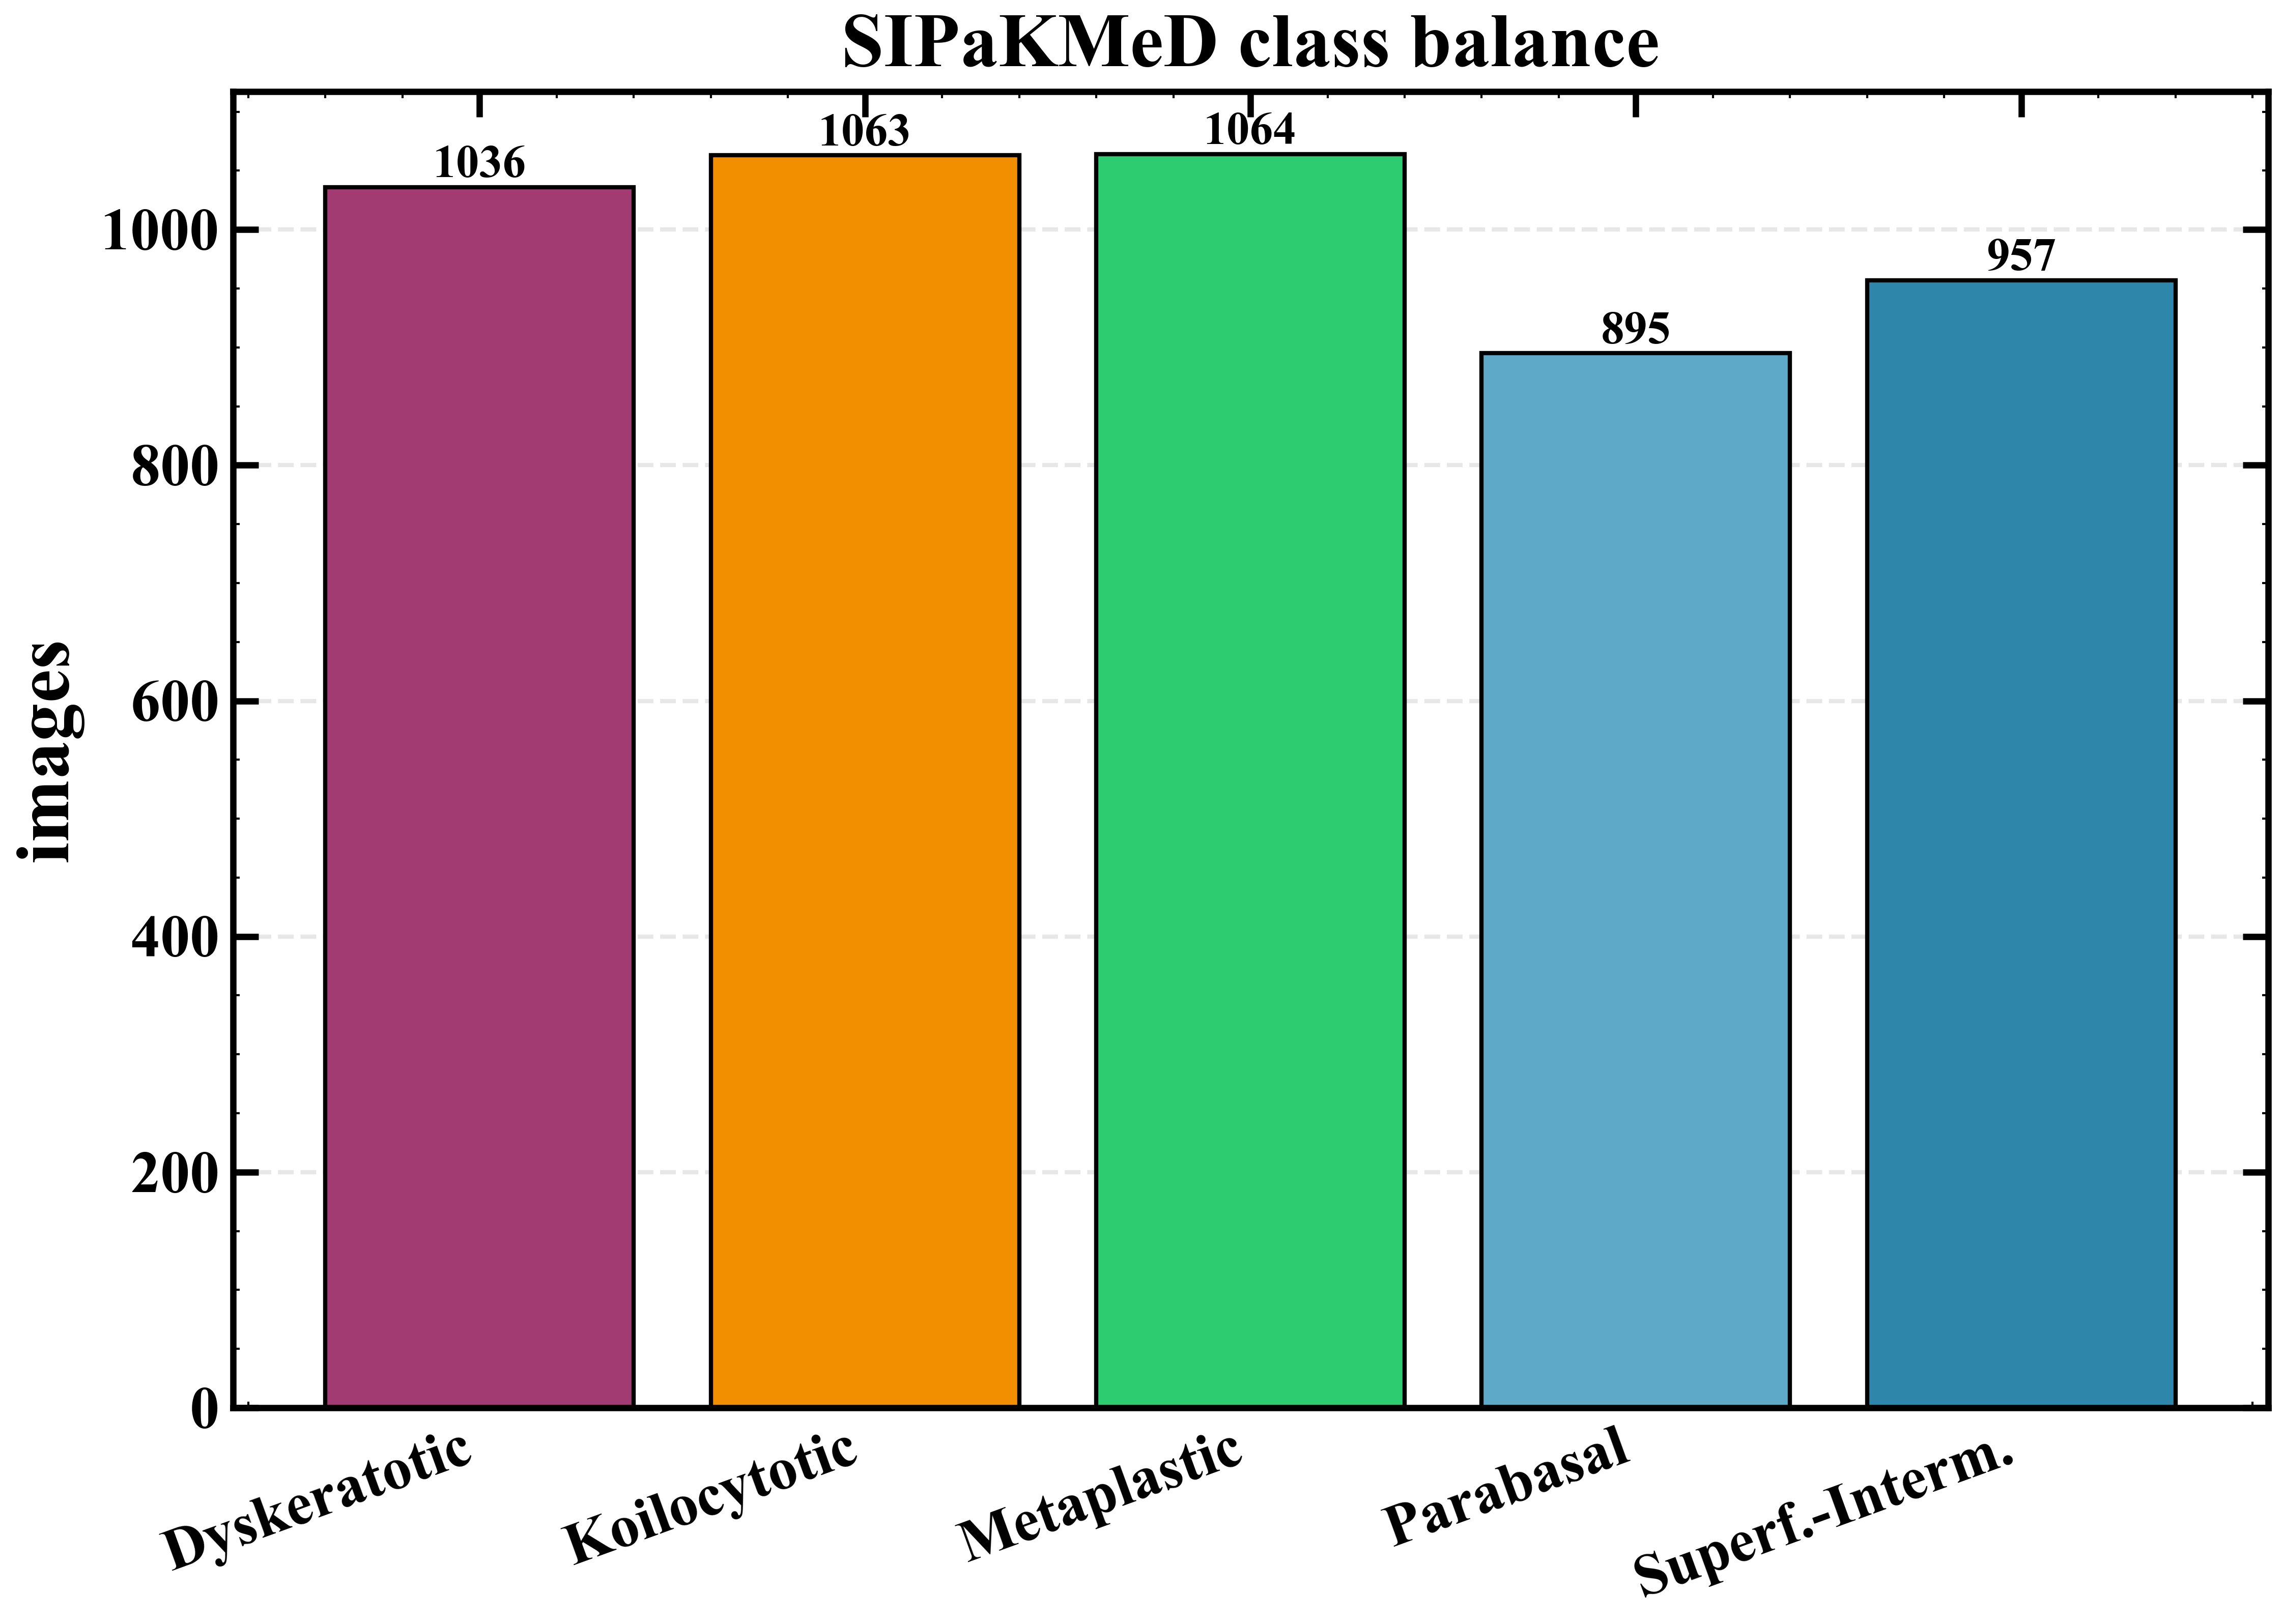

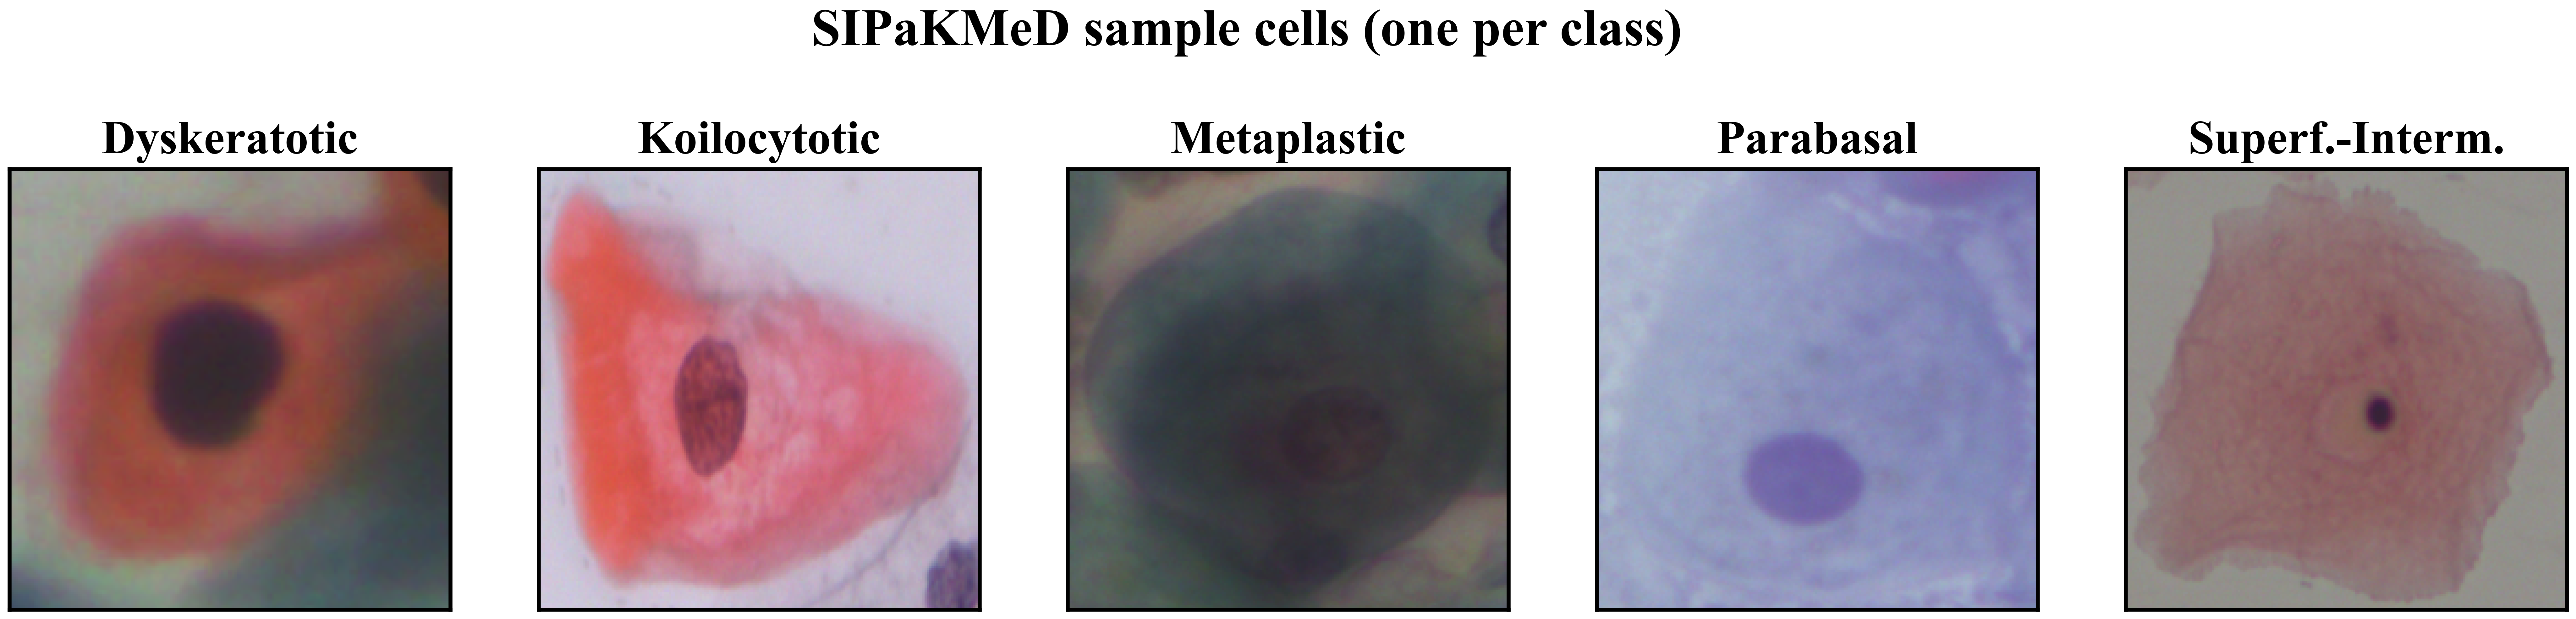

In [2]:
import eda
summary = eda.analyze()
show(os.path.join(FIG, 'eda_class_balance'), os.path.join(FIG, 'eda_sample_cells'))

## 2. Full training — B4 teacher (two-stage) -> distilled B0 student
Clean **tqdm** progress per epoch; early stopping restores the best weights.

**Per epoch it saves:** `checkpoints/<stage>_best.pt` (best val) + `checkpoints/<stage>_last.pt` (recovery), the timestamped `logs/run_<ts>.json`, and per-stage `metrics/history_<stage>.json`. Final weights -> `teacher_b4.pt`, `student_b0.pt`, consolidated `metrics/train_histories.json`, and the train/val **loss + accuracy curves**.

*This is the long cell (a few hours).* **If interrupted, just re-run it — it auto-resumes.** Options: `train.main(smoke=True)` (2-epoch dry run), `train.main(fresh=True)` (ignore old checkpoints, restart).

In [3]:
import train
train.main()        # auto-resumes; smoke=True for a 2-epoch check, fresh=True to restart from scratch

Run id: 20260621_221242  ->  f:\Cervaical Cancer\Legacy_src\results\logs\run_20260621_221242.json
Class counts: {'Dyskeratotic': 1036, 'Koilocytotic': 1063, 'Metaplastic': 1064, 'Parabasal': 895, 'Superficial-Intermediate': 957} | total 5015


f:\Cervaical Cancer\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Teacher params: 18.5M
[teacher-s1] resuming at epoch 15/30 (best val_loss=0.27151042656789154)


[teacher-s1] ep 15/30  loss=0.3320 val_loss=0.2986  acc=0.8774 val_acc=0.8933  lr=1.0e-03  (133s)


[teacher-s1] ep 16/30  loss=0.3005 val_loss=0.2790  acc=0.8824 val_acc=0.8883  lr=3.0e-04  (97s)


...

[student-kd] ep 30/40  loss=0.7507 val_loss=0.0935  acc=0.9621 val_acc=0.9621  lr=5.0e-05  (76s)


[student-kd] ep 31/40  loss=0.7203 val_loss=0.0990  acc=0.9676 val_acc=0.9611  lr=5.0e-05  (75s)


[student-kd] ep 32/40  loss=0.7413 val_loss=0.1004  acc=0.9681 val_acc=0.9631  lr=5.0e-05  (78s)


[student-kd] ep 33/40  loss=0.7198 val_loss=0.0919  acc=0.9686 val_acc=0.9651  lr=5.0e-05  (81s)


[student-kd] ep 34/40  loss=0.7022 val_loss=0.1043  acc=0.9673 val_acc=0.9611  lr=5.0e-05  (86s)
[student-kd] early stop at ep 34 (best val_accuracy=0.9661 @ ep26)
== Student final val_acc = 0.9661 ==
Saved histories -> f:\Cervaical Cancer\Legacy_src\results\metrics\train_histories.json
Saved run log   -> f:\Cervaical Cancer\Legacy_src\results\logs\run_20260621_221242.json
Saved curves    -> results/figures/{teacher,student}_training_curves.(pdf|png)


## 3. Training curves (train vs. val loss & accuracy)

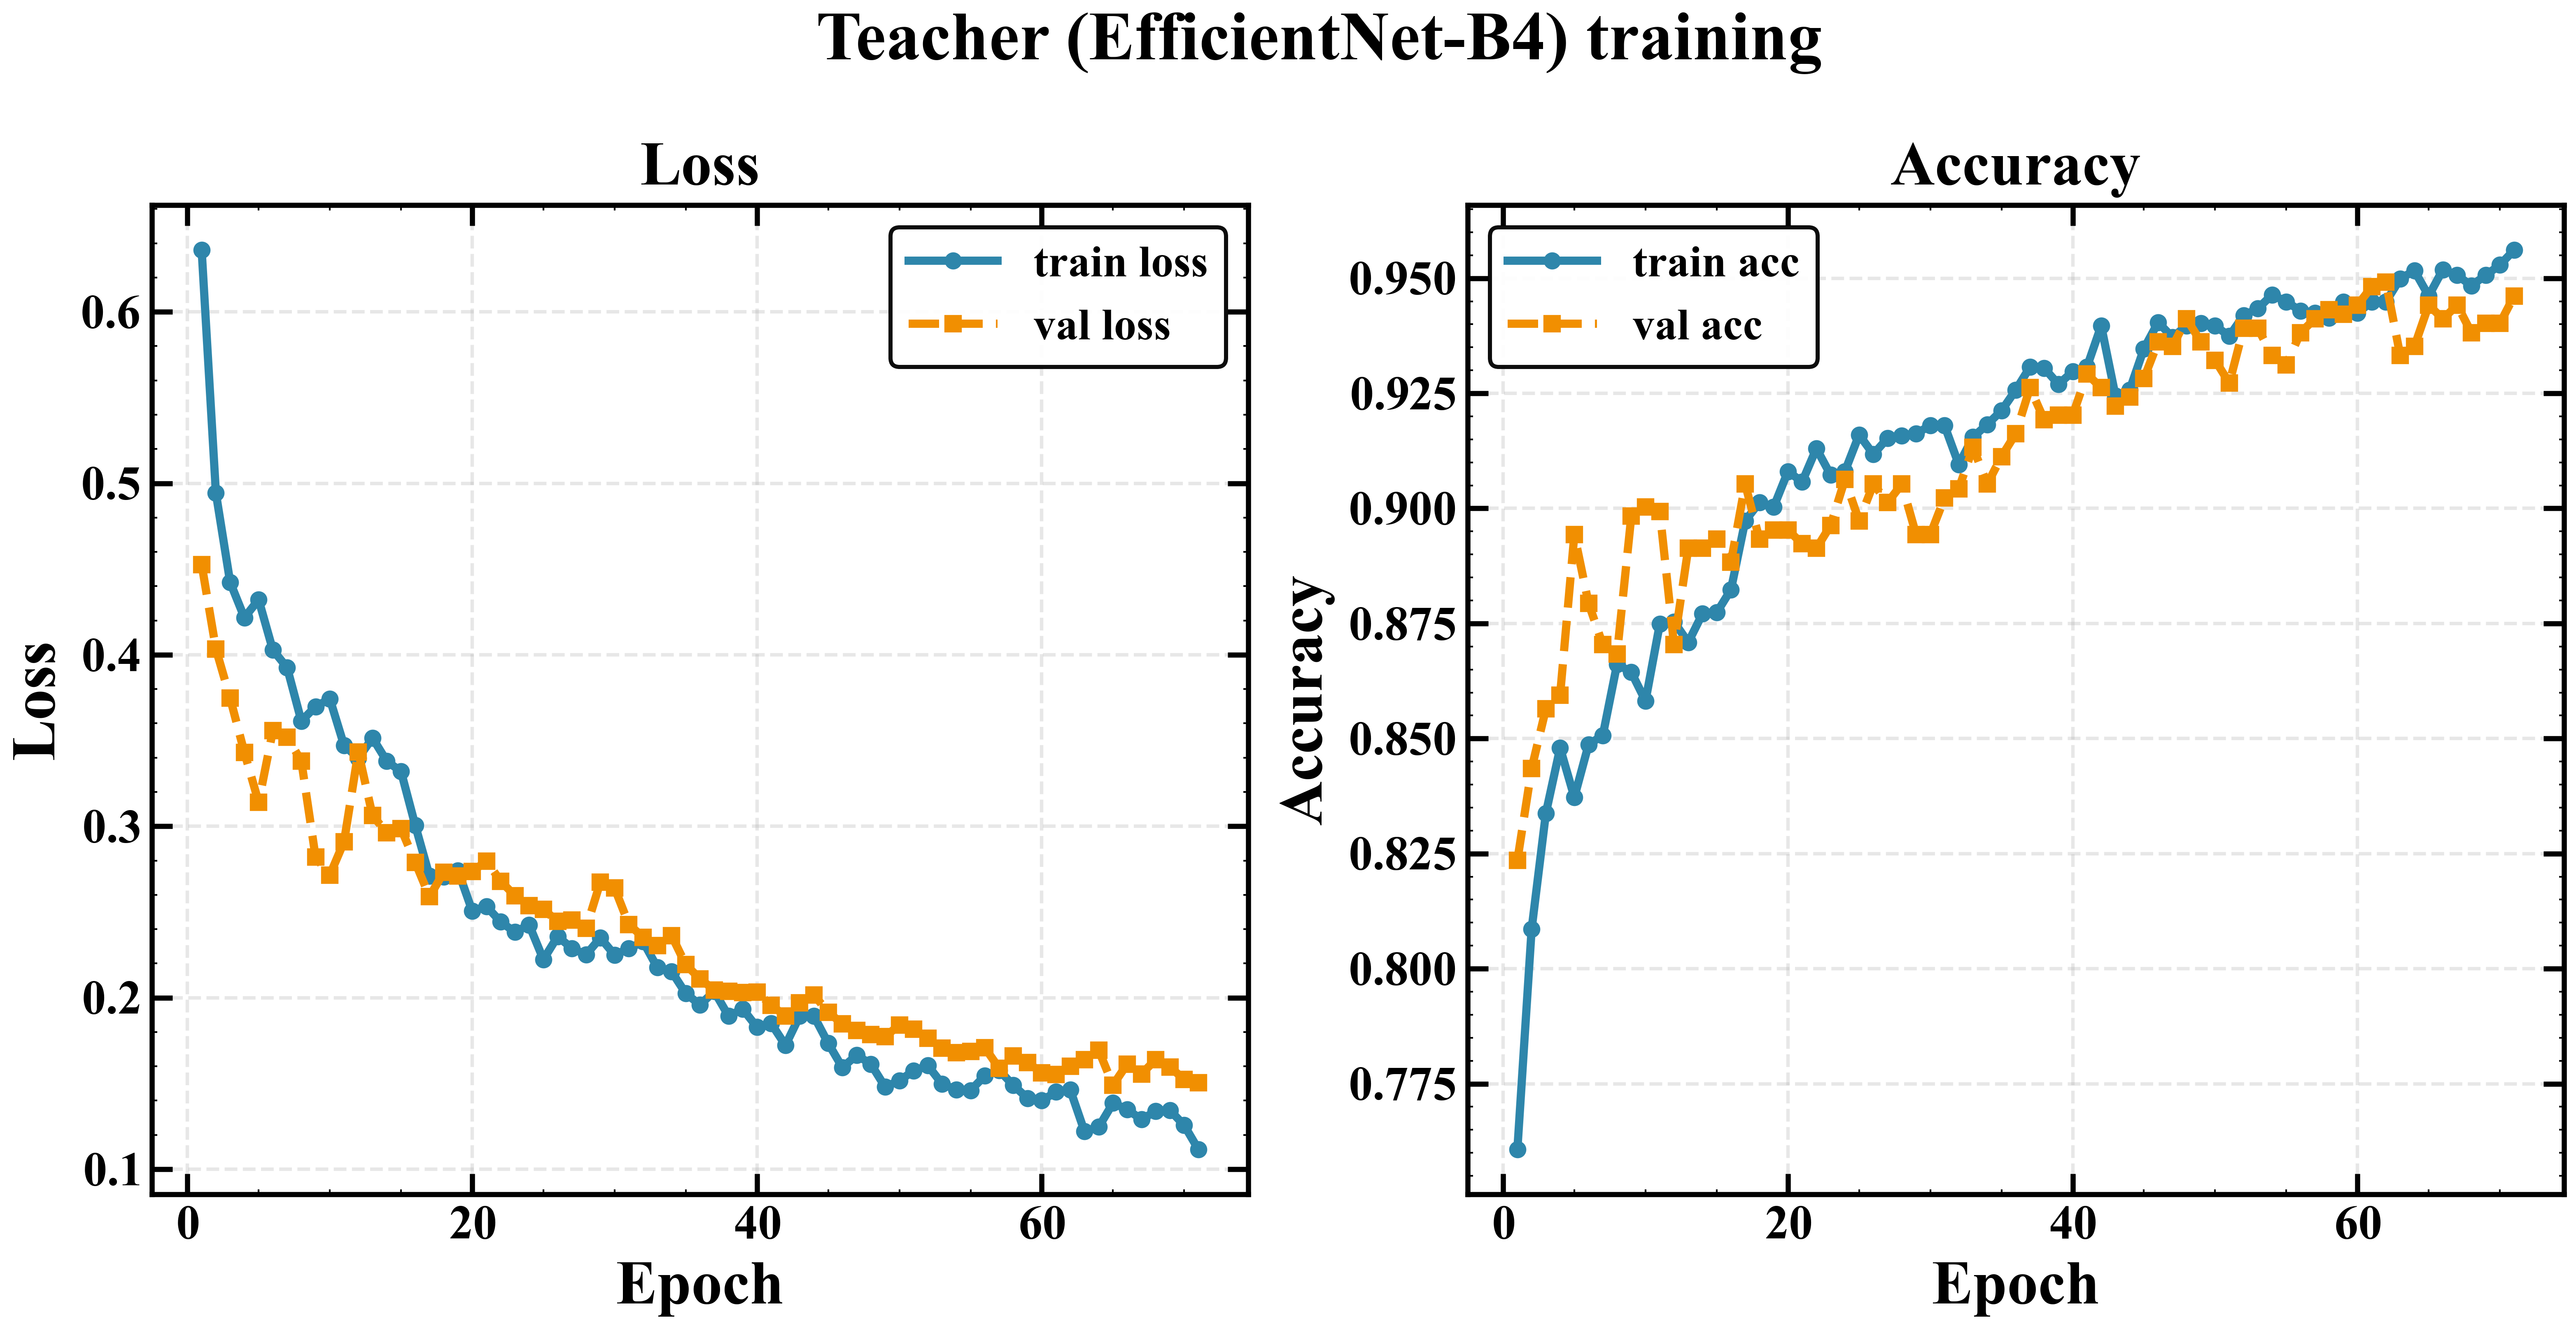

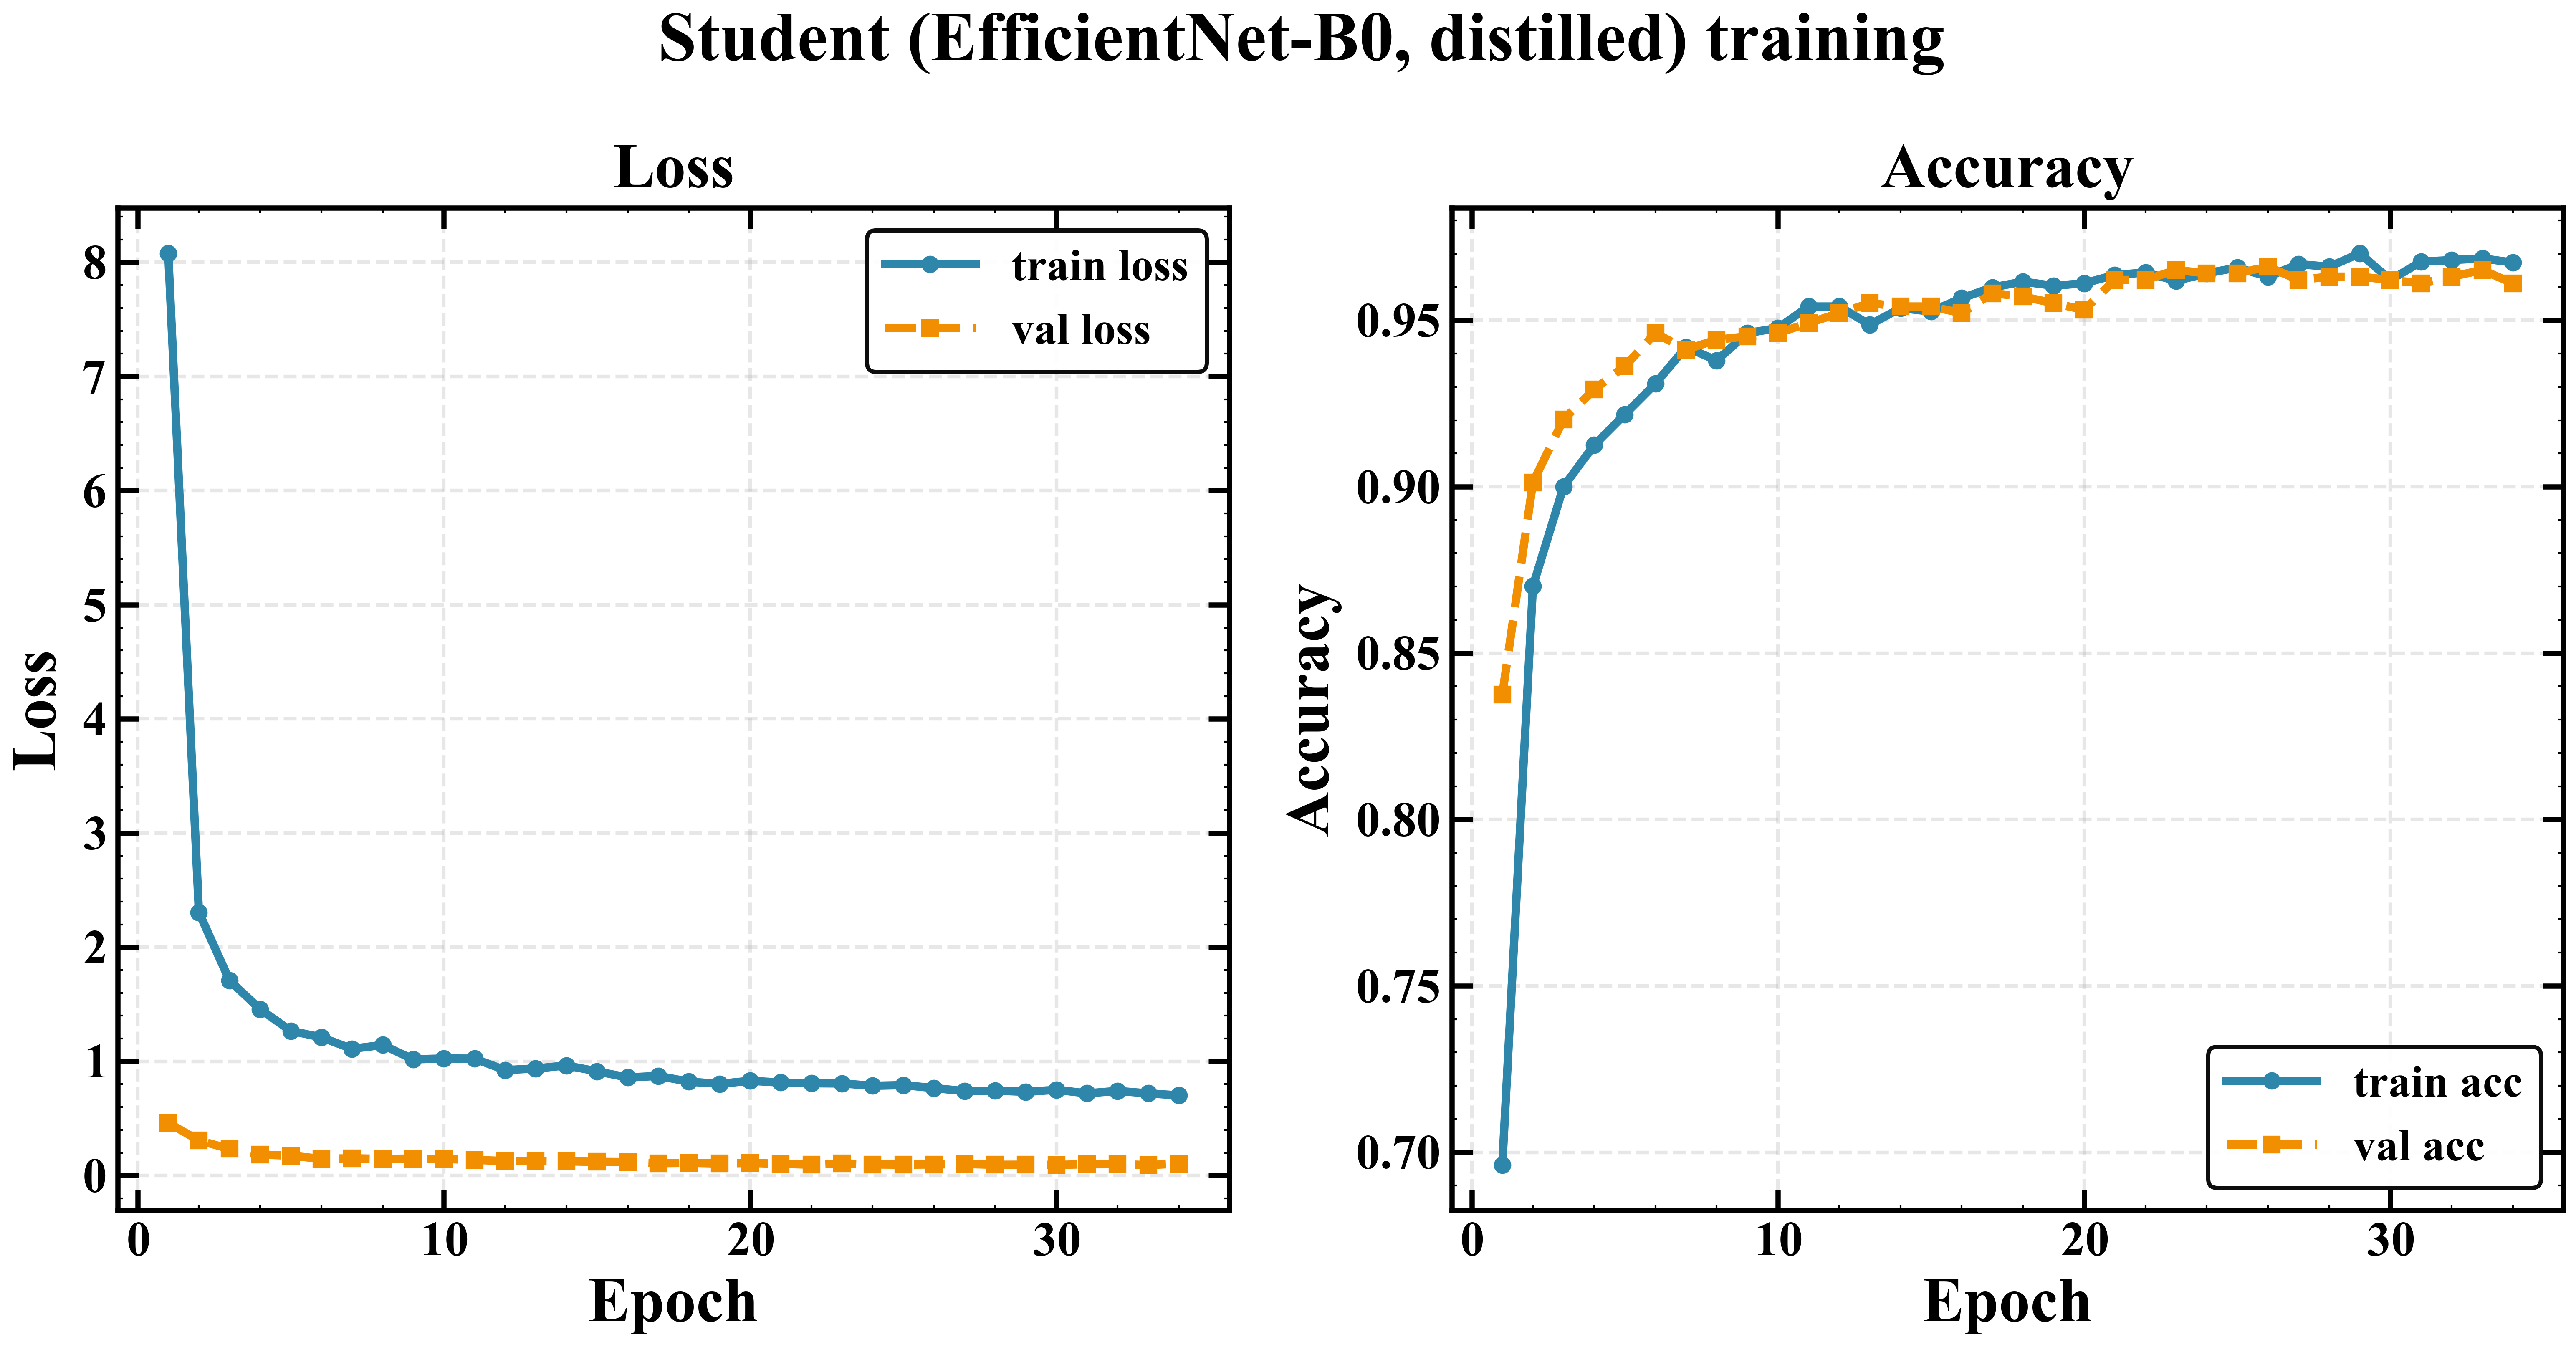

In [4]:
show(os.path.join(FIG, 'teacher_training_curves'), os.path.join(FIG, 'student_training_curves'))

## 4. In-distribution evaluation (SIPaKMeD val, all metrics)
Accuracy, balanced accuracy, macro-F1, Cohen's kappa, one-vs-rest macro AUROC, ECE, per-class report,
confusion matrix, ROC curves, reliability diagram — for both teacher and student. Targets ~97% / ~97.5%.
Raw predictions are saved to `metrics/predictions_<model>.json` so these figures can be rebuilt later.

[in-dist teacher] acc=0.9432 bal_acc=0.9458 macroF1=0.9449 kappa=0.9289 AUROC=0.9955 ECE=0.0131
[in-dist student] acc=0.9661 bal_acc=0.9680 macroF1=0.9671 kappa=0.9576 AUROC=0.9981 ECE=0.0152


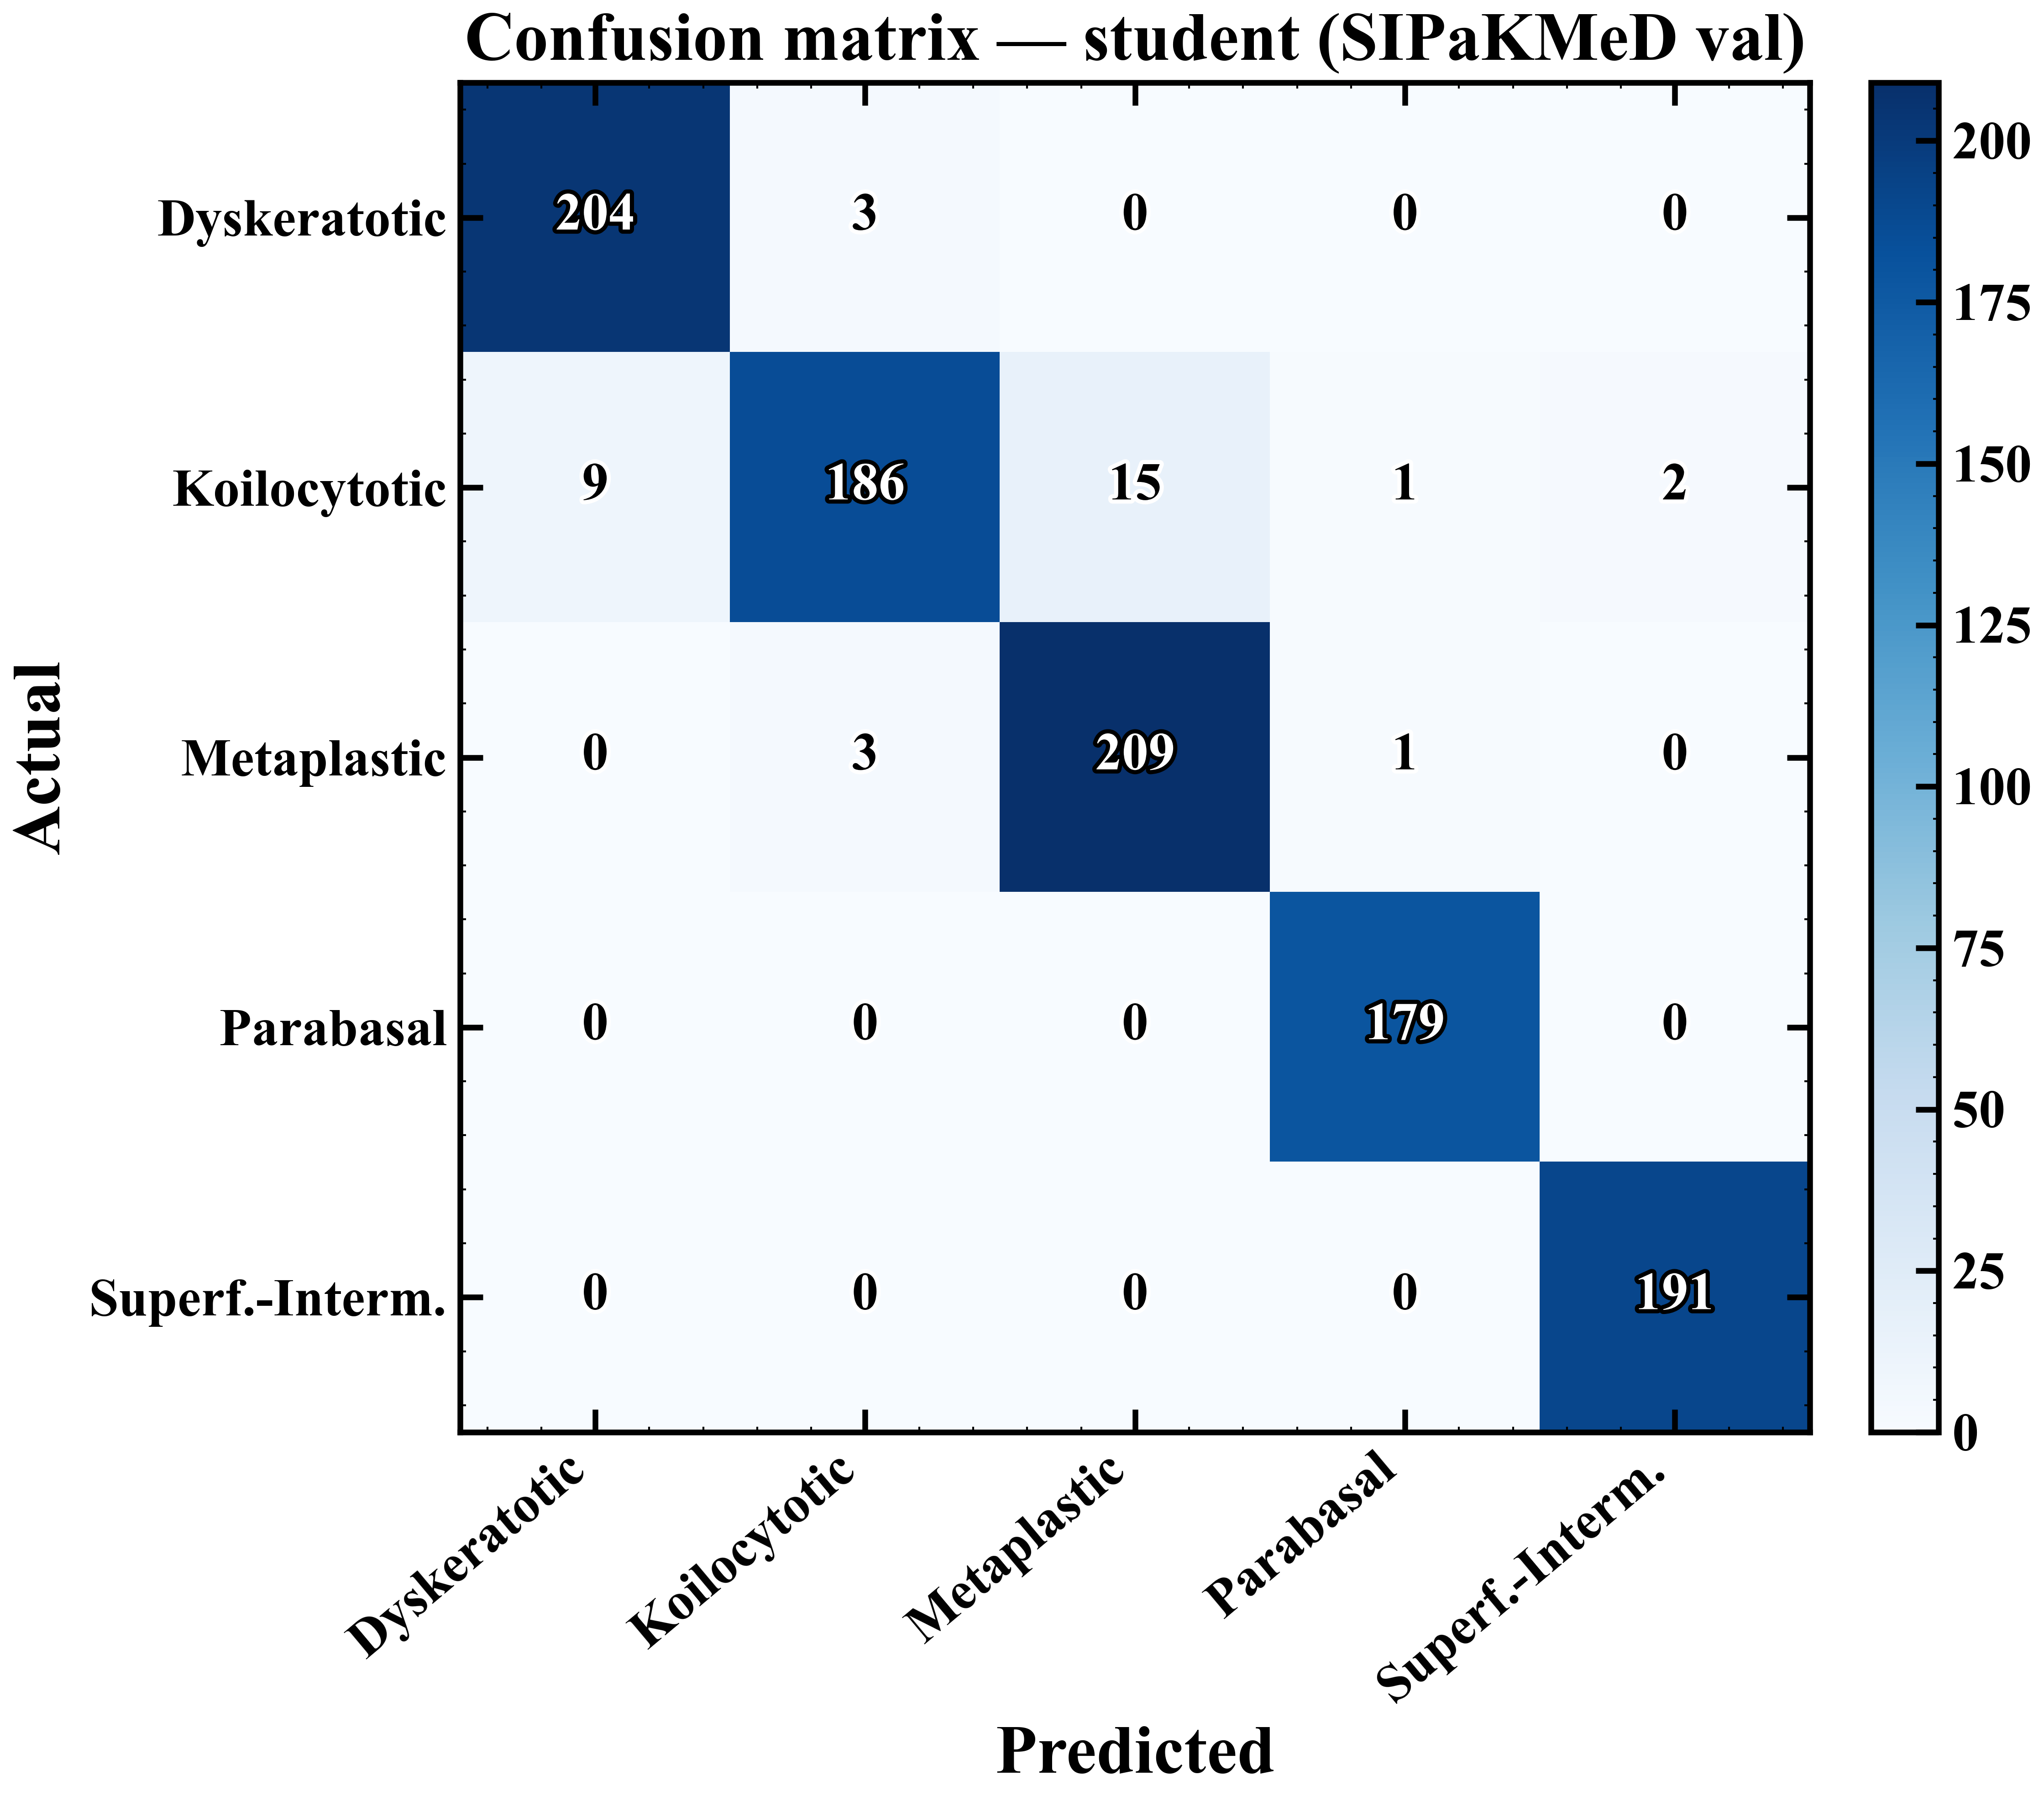

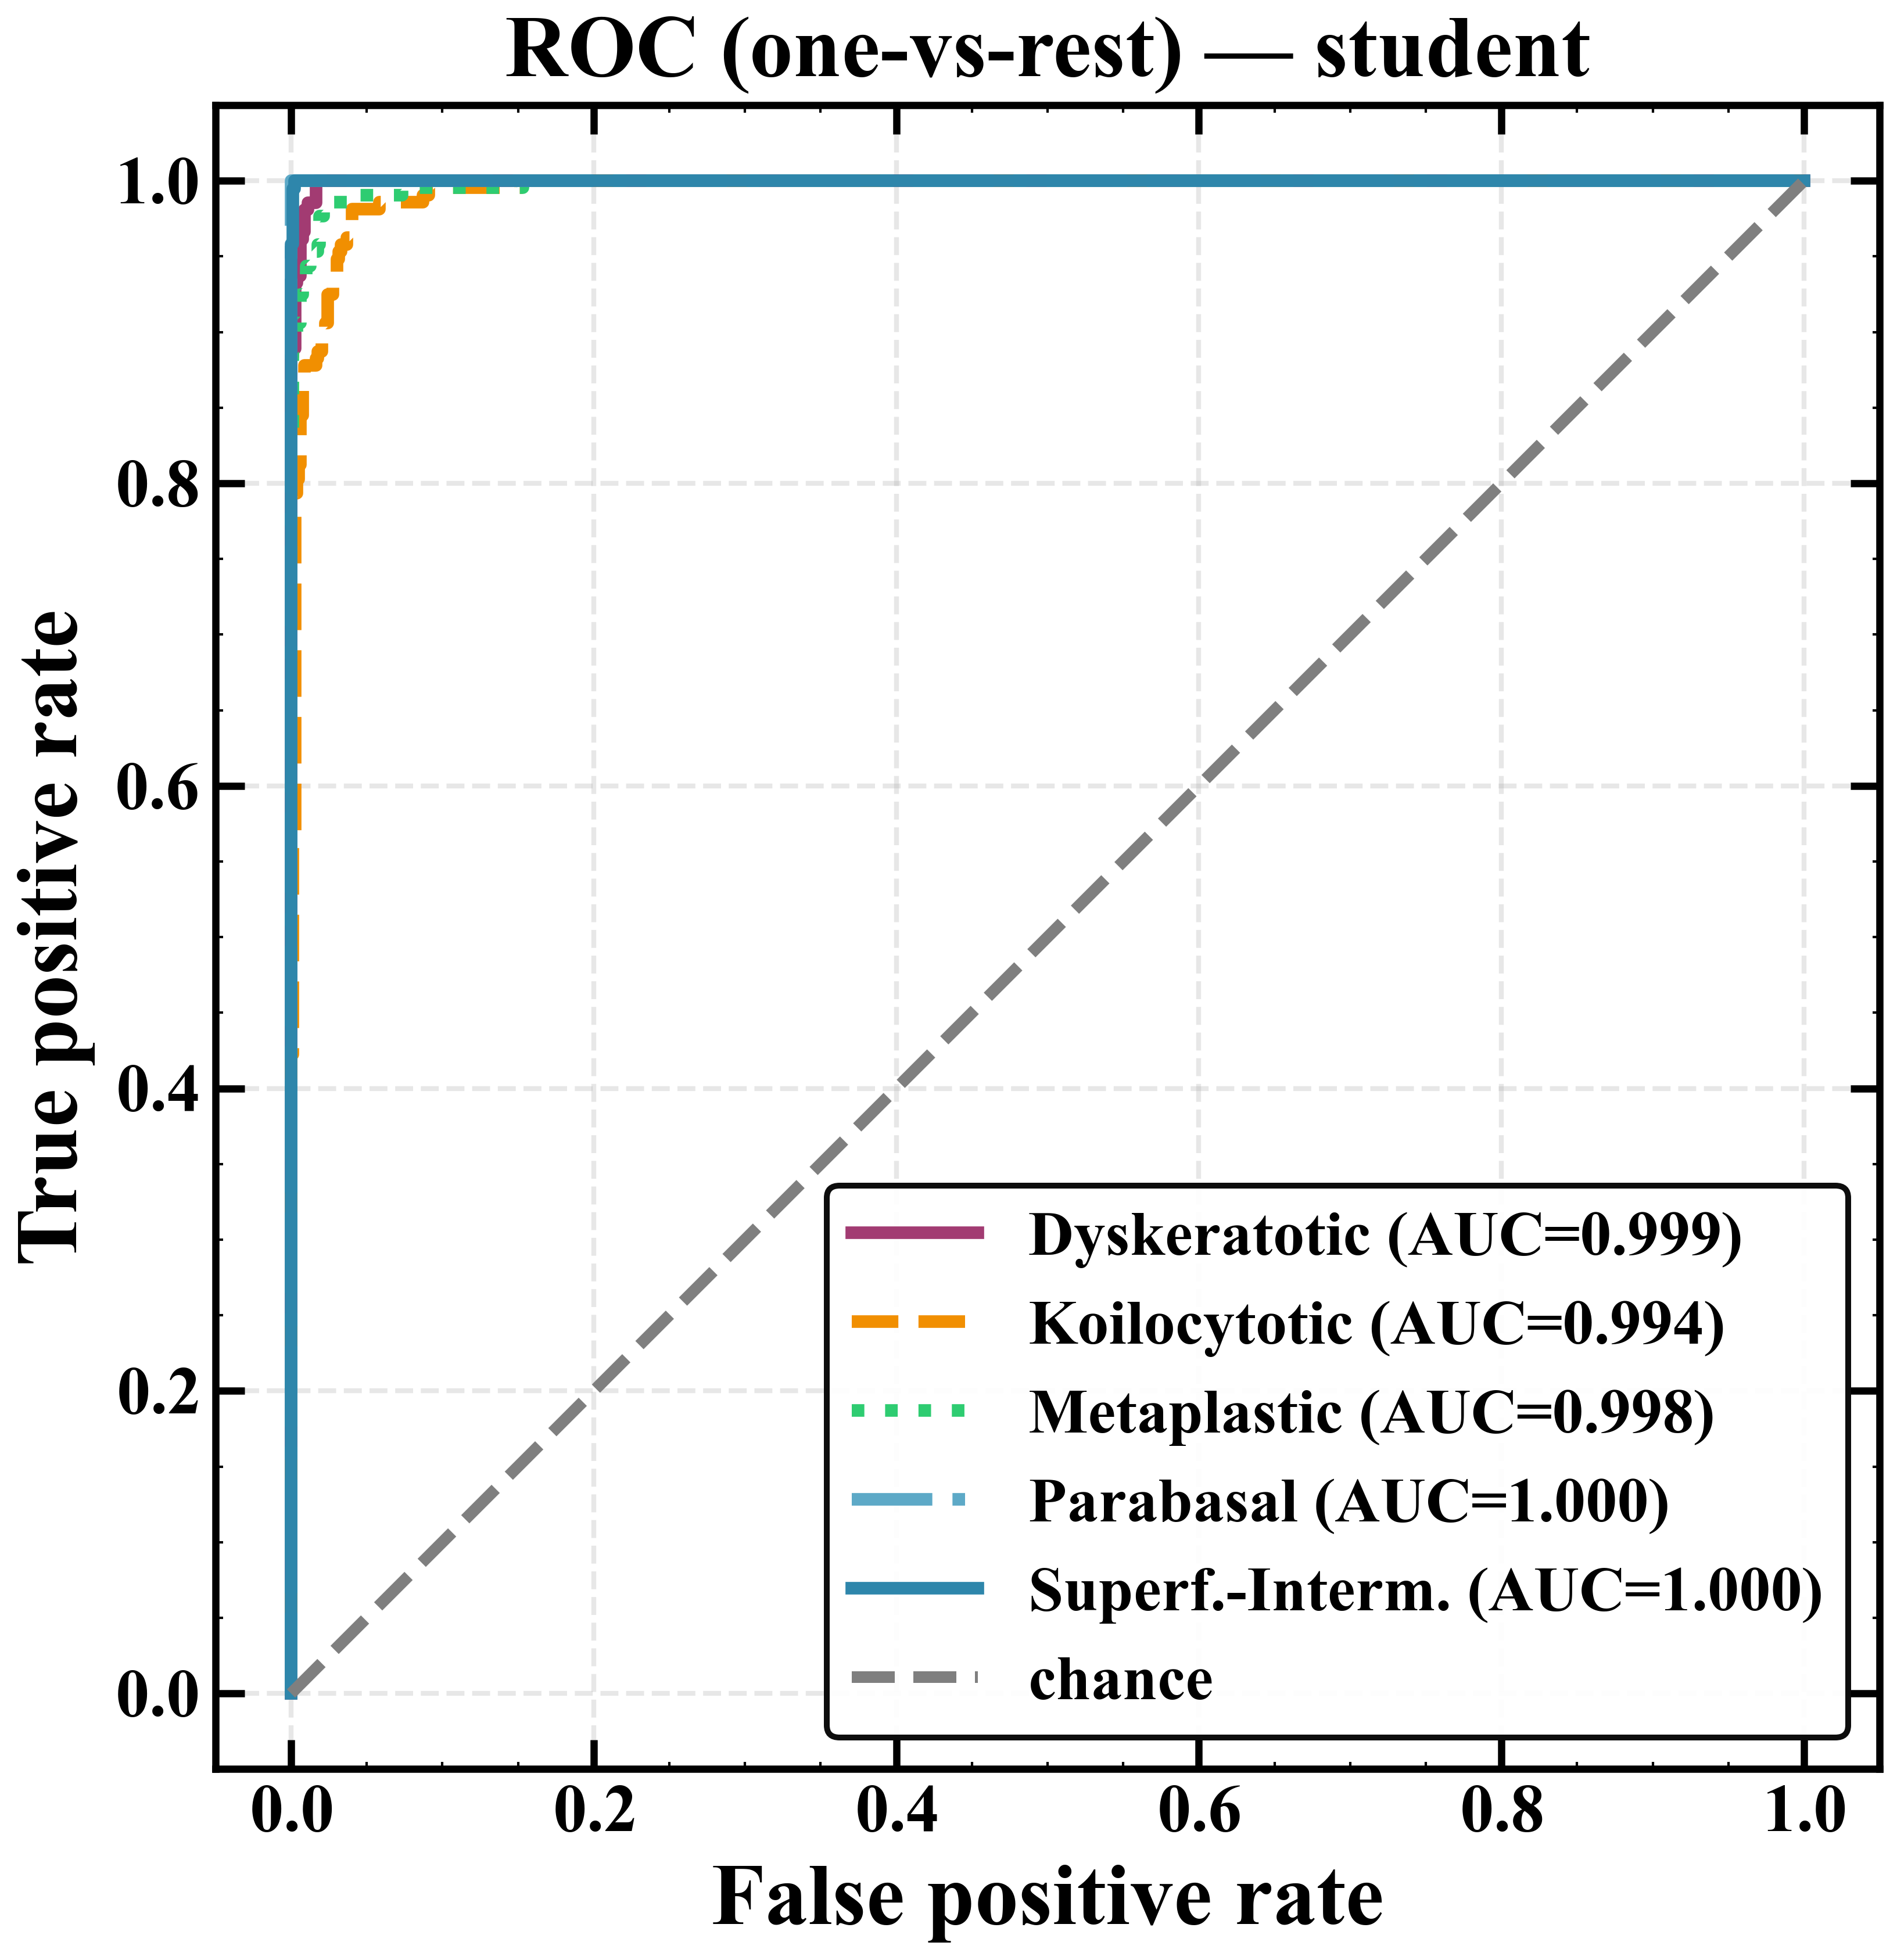

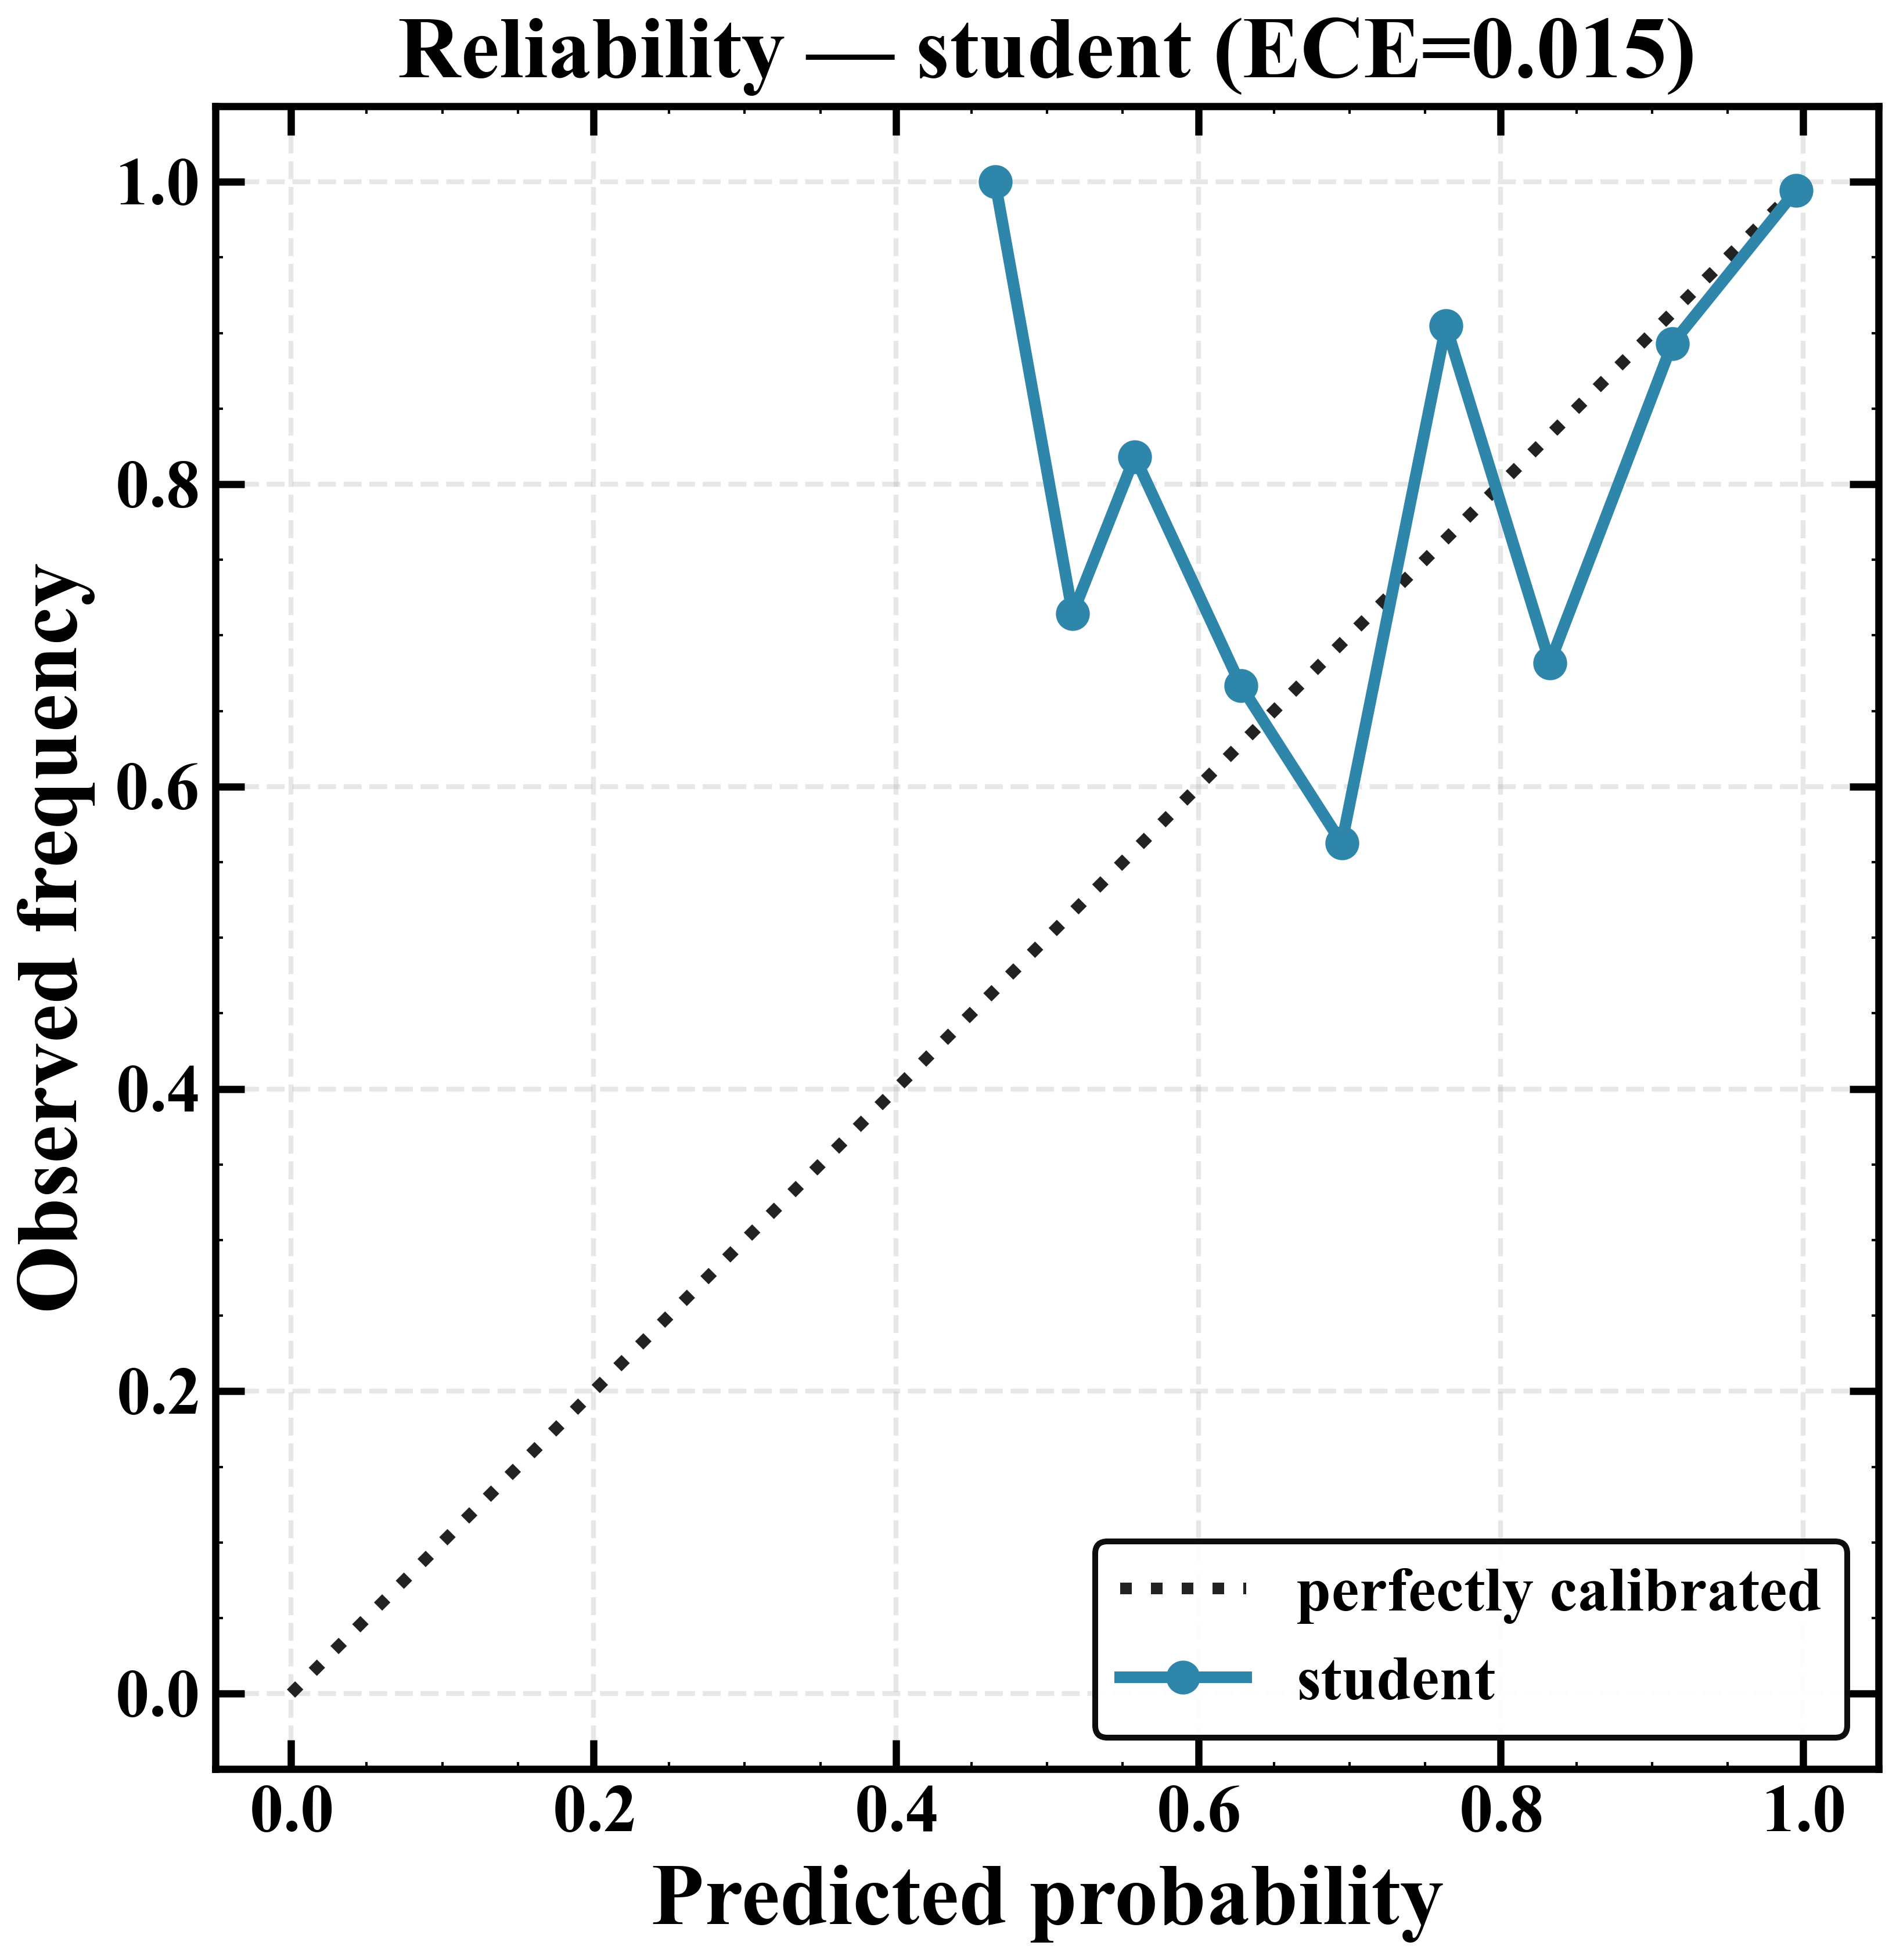

In [2]:
import evaluate
m_teacher = evaluate.indist_eval('teacher')
m_student = evaluate.indist_eval('student')
show(os.path.join(FIG, 'cm_student'), os.path.join(FIG, 'roc_student'), os.path.join(FIG, 'reliability_student'))

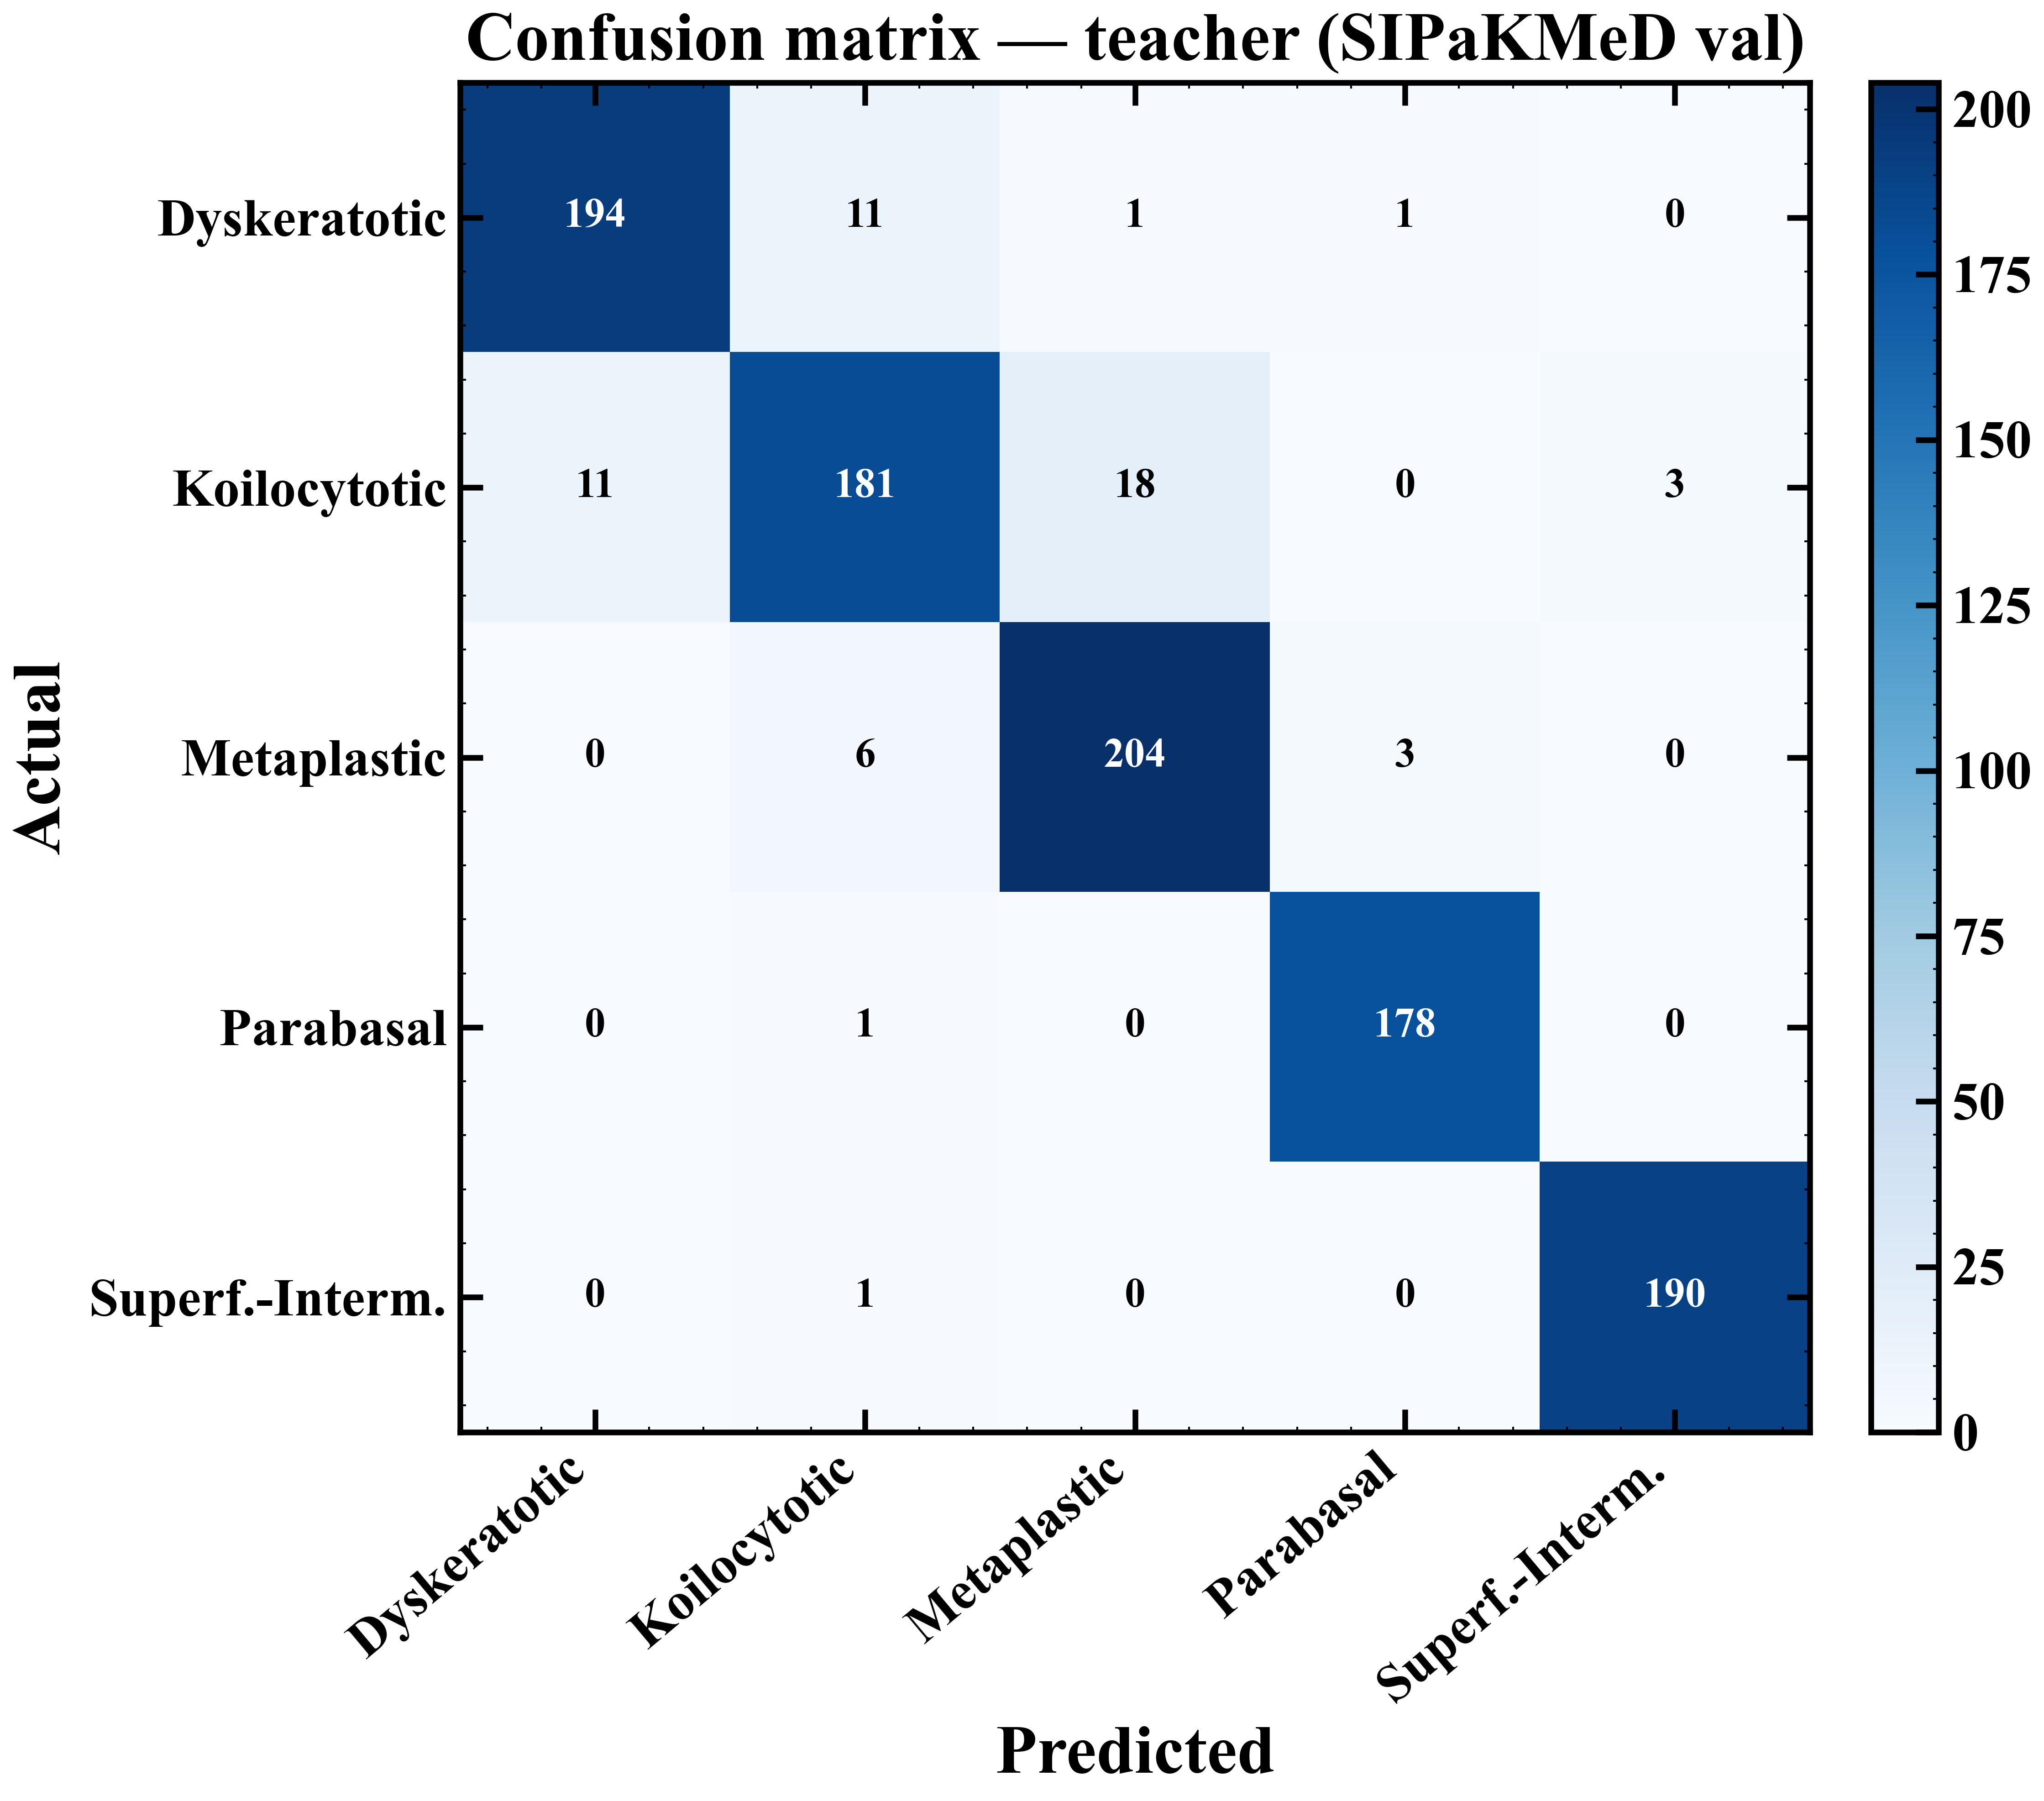

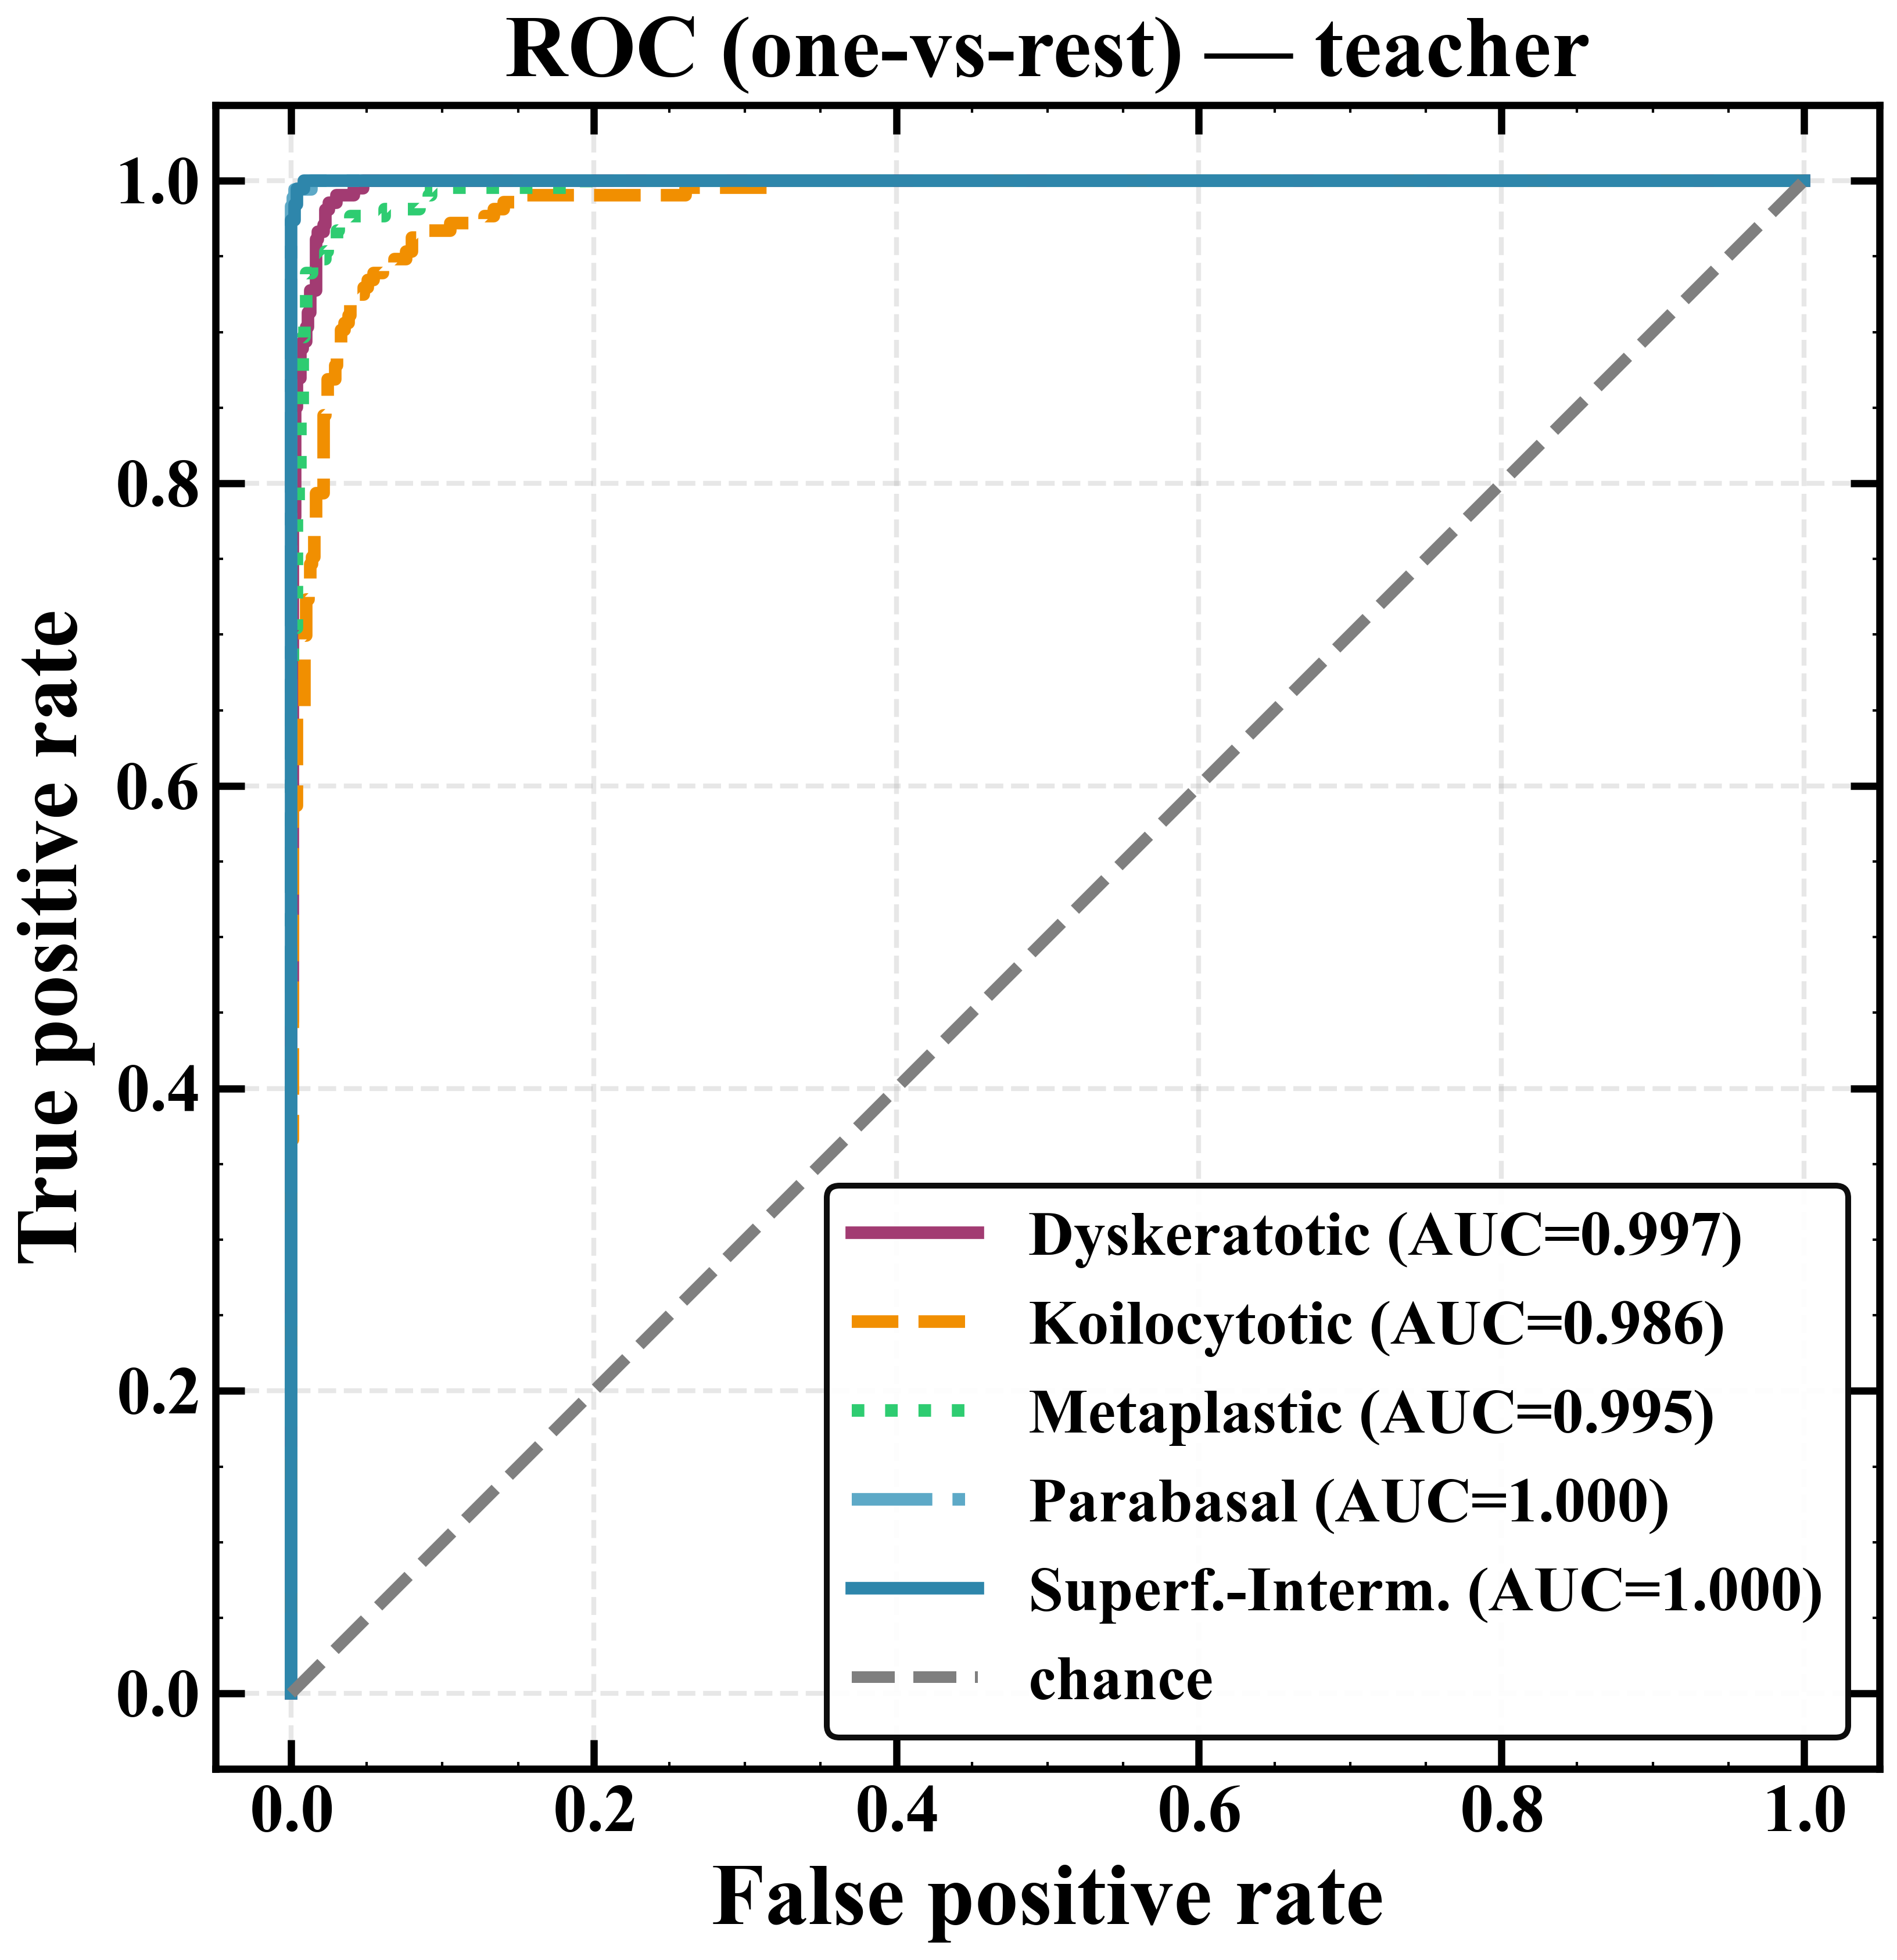

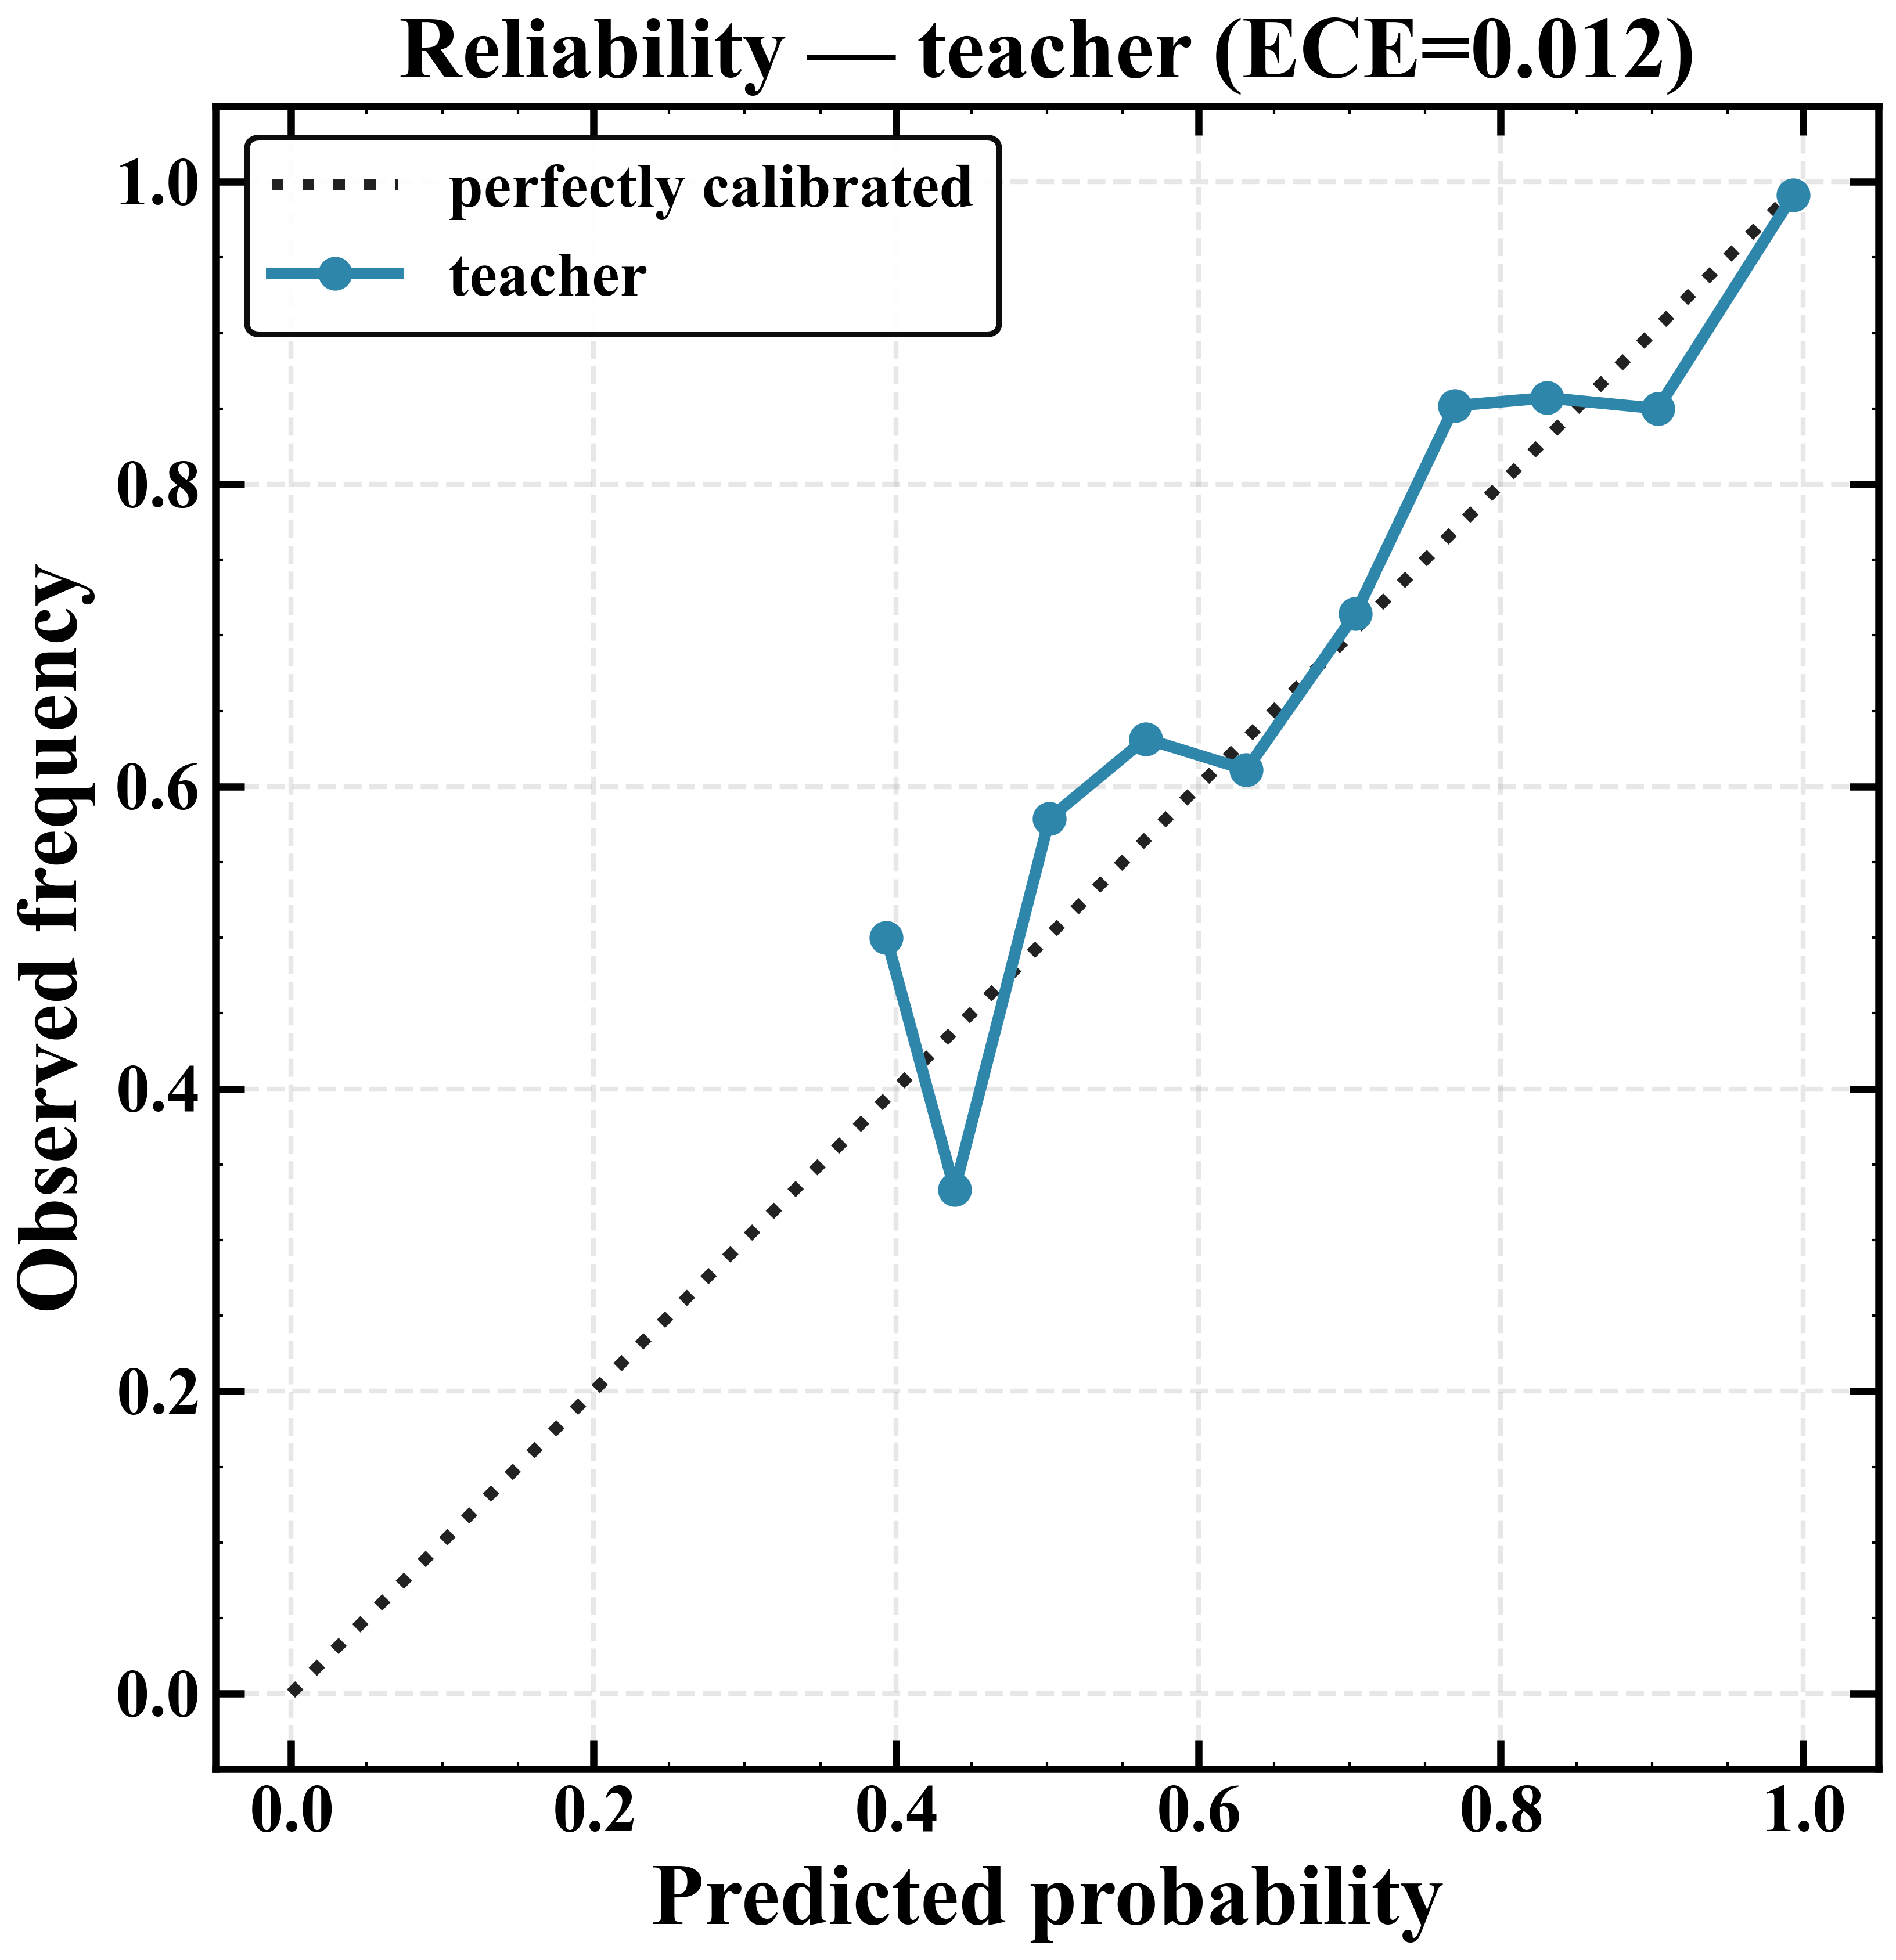

In [6]:
# teacher figures too
show(os.path.join(FIG, 'cm_teacher'), os.path.join(FIG, 'roc_teacher'), os.path.join(FIG, 'reliability_teacher'))

## 5. Download external evaluation datasets
Best-effort fetch of **Herlev / APACC / HiCervix** into `data/raw/`. Failures are non-fatal — the cross-dataset
step below simply skips anything not present. (Herlev needs Kaggle creds; APACC needs `osfclient`.)

In [4]:
import download_datasets
status = download_datasets.download_all()
print('download status:', status)

[Herlev] already present at f:\Cervaical Cancer\data\raw\herlev (1834 images) — skipping (force=True to re-download)
[HiCervix] already present at f:\Cervaical Cancer\data\raw\hicervix (40229 images) — skipping (force=True to re-download)
[APACC] already present at f:\Cervaical Cancer\data\raw\apacc (1126 images) — skipping (force=True to re-download)
download status: {'herlev': True, 'hicervix': True, 'apacc': True}


## 6. Cross-dataset evaluation (binary Normal vs. Abnormal)
The SIPaKMeD-trained **student** is applied to each external set; the 5-class output is collapsed to
P(abnormal) = P(Koilocytotic)+P(Dyskeratotic). Reports accuracy, balanced accuracy, sensitivity, specificity, AUROC.

[cross herlev] n=917 acc=0.639 bal_acc=0.651 sens=0.625 spec=0.678 AUROC=0.727517600244873
[cross apacc] n=1125 acc=0.532 bal_acc=0.535 sens=0.654 spec=0.417 AUROC=0.5254677064359441
[cross hicervix] n=4823 acc=0.605 bal_acc=0.562 sens=0.386 spec=0.738 AUROC=0.594012962366169


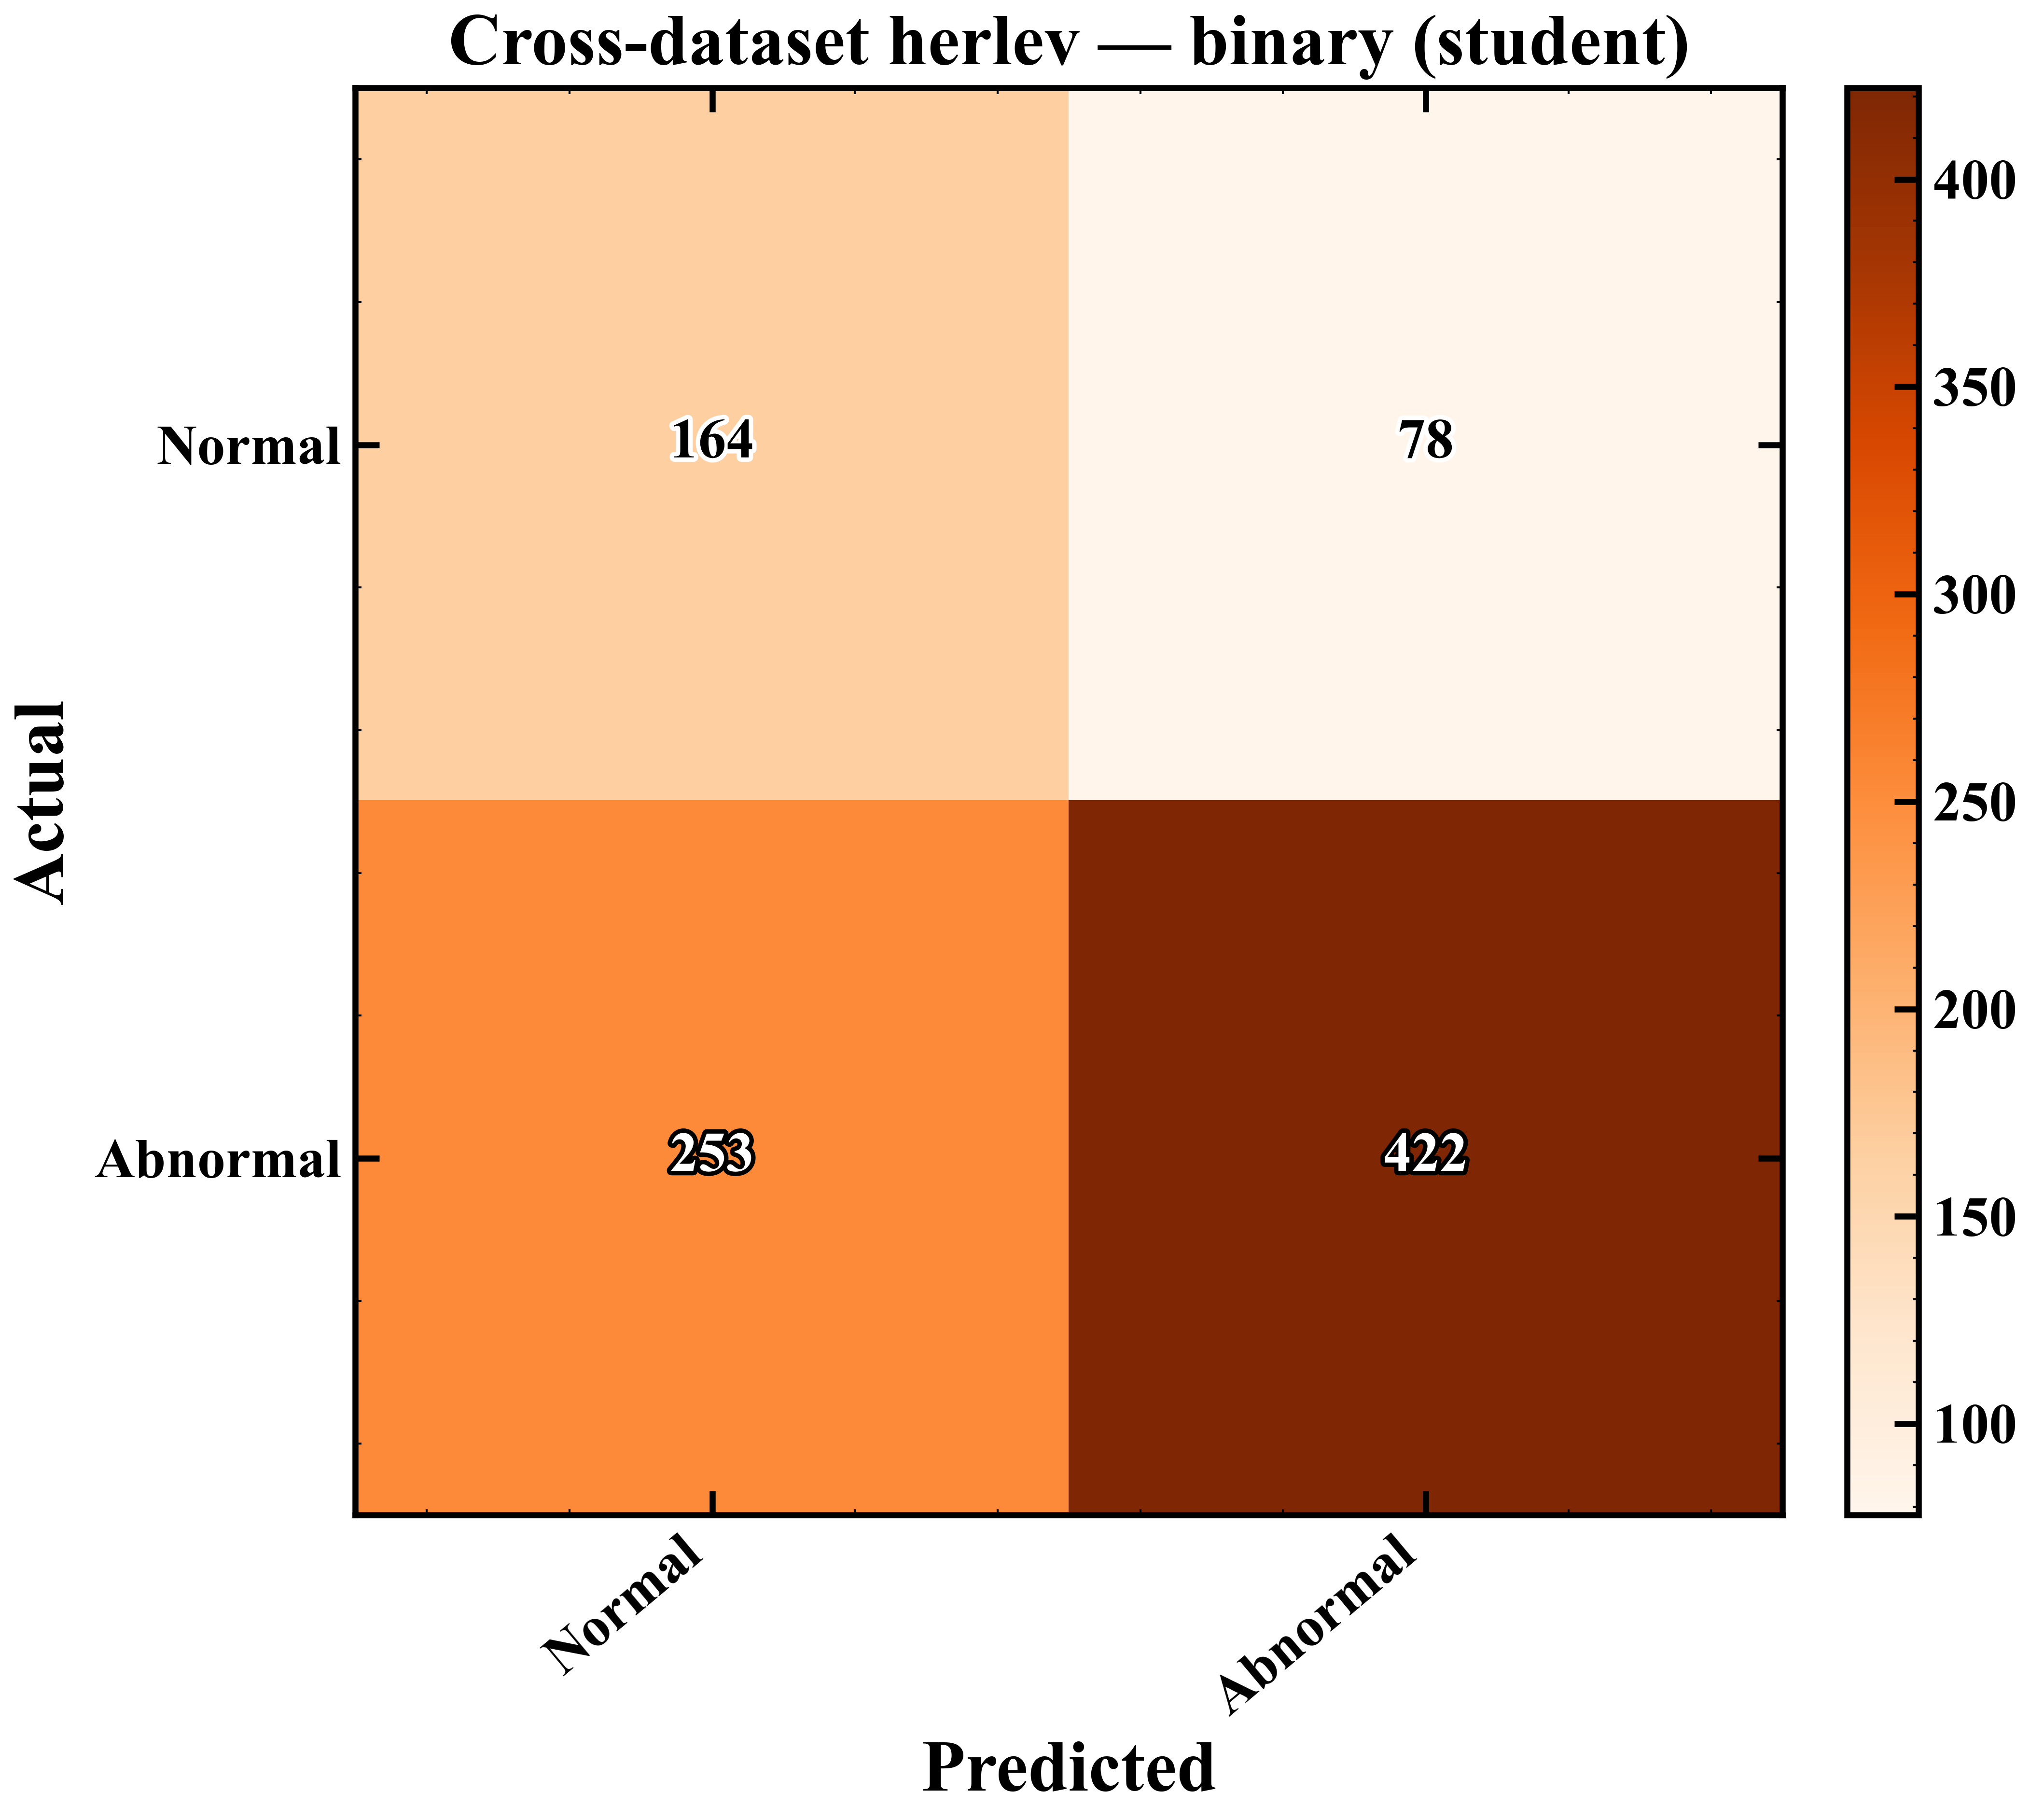

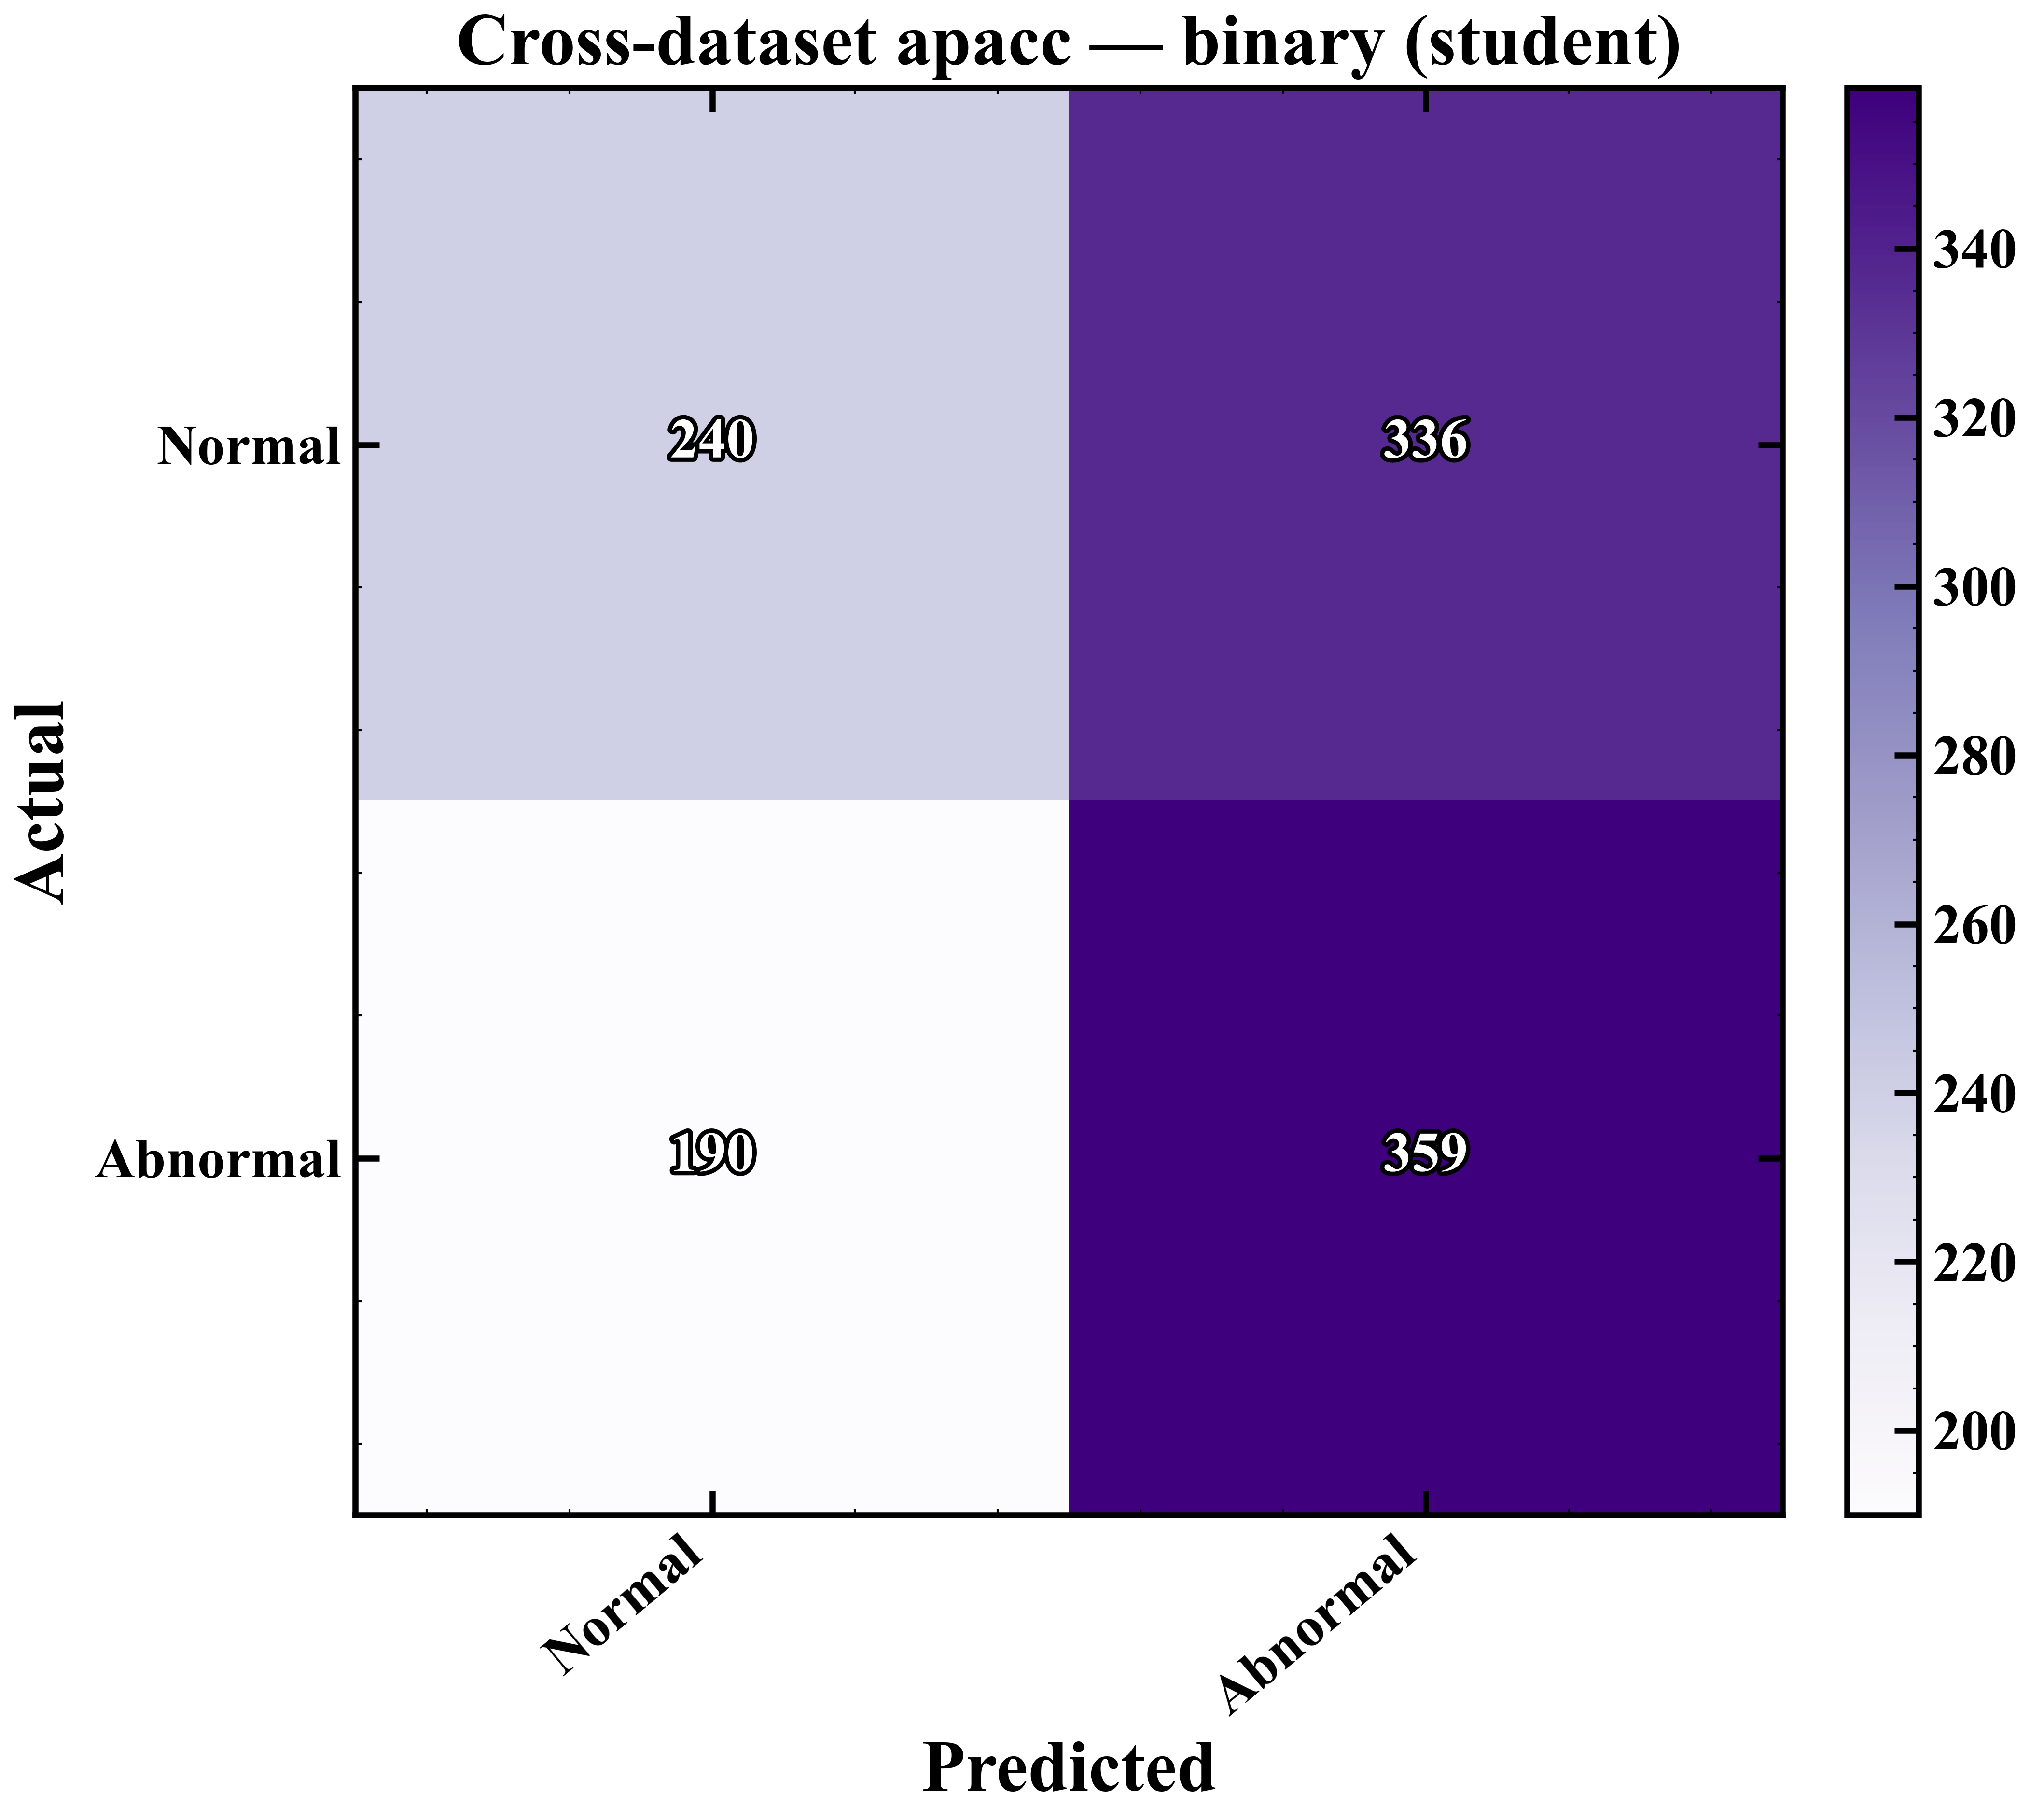

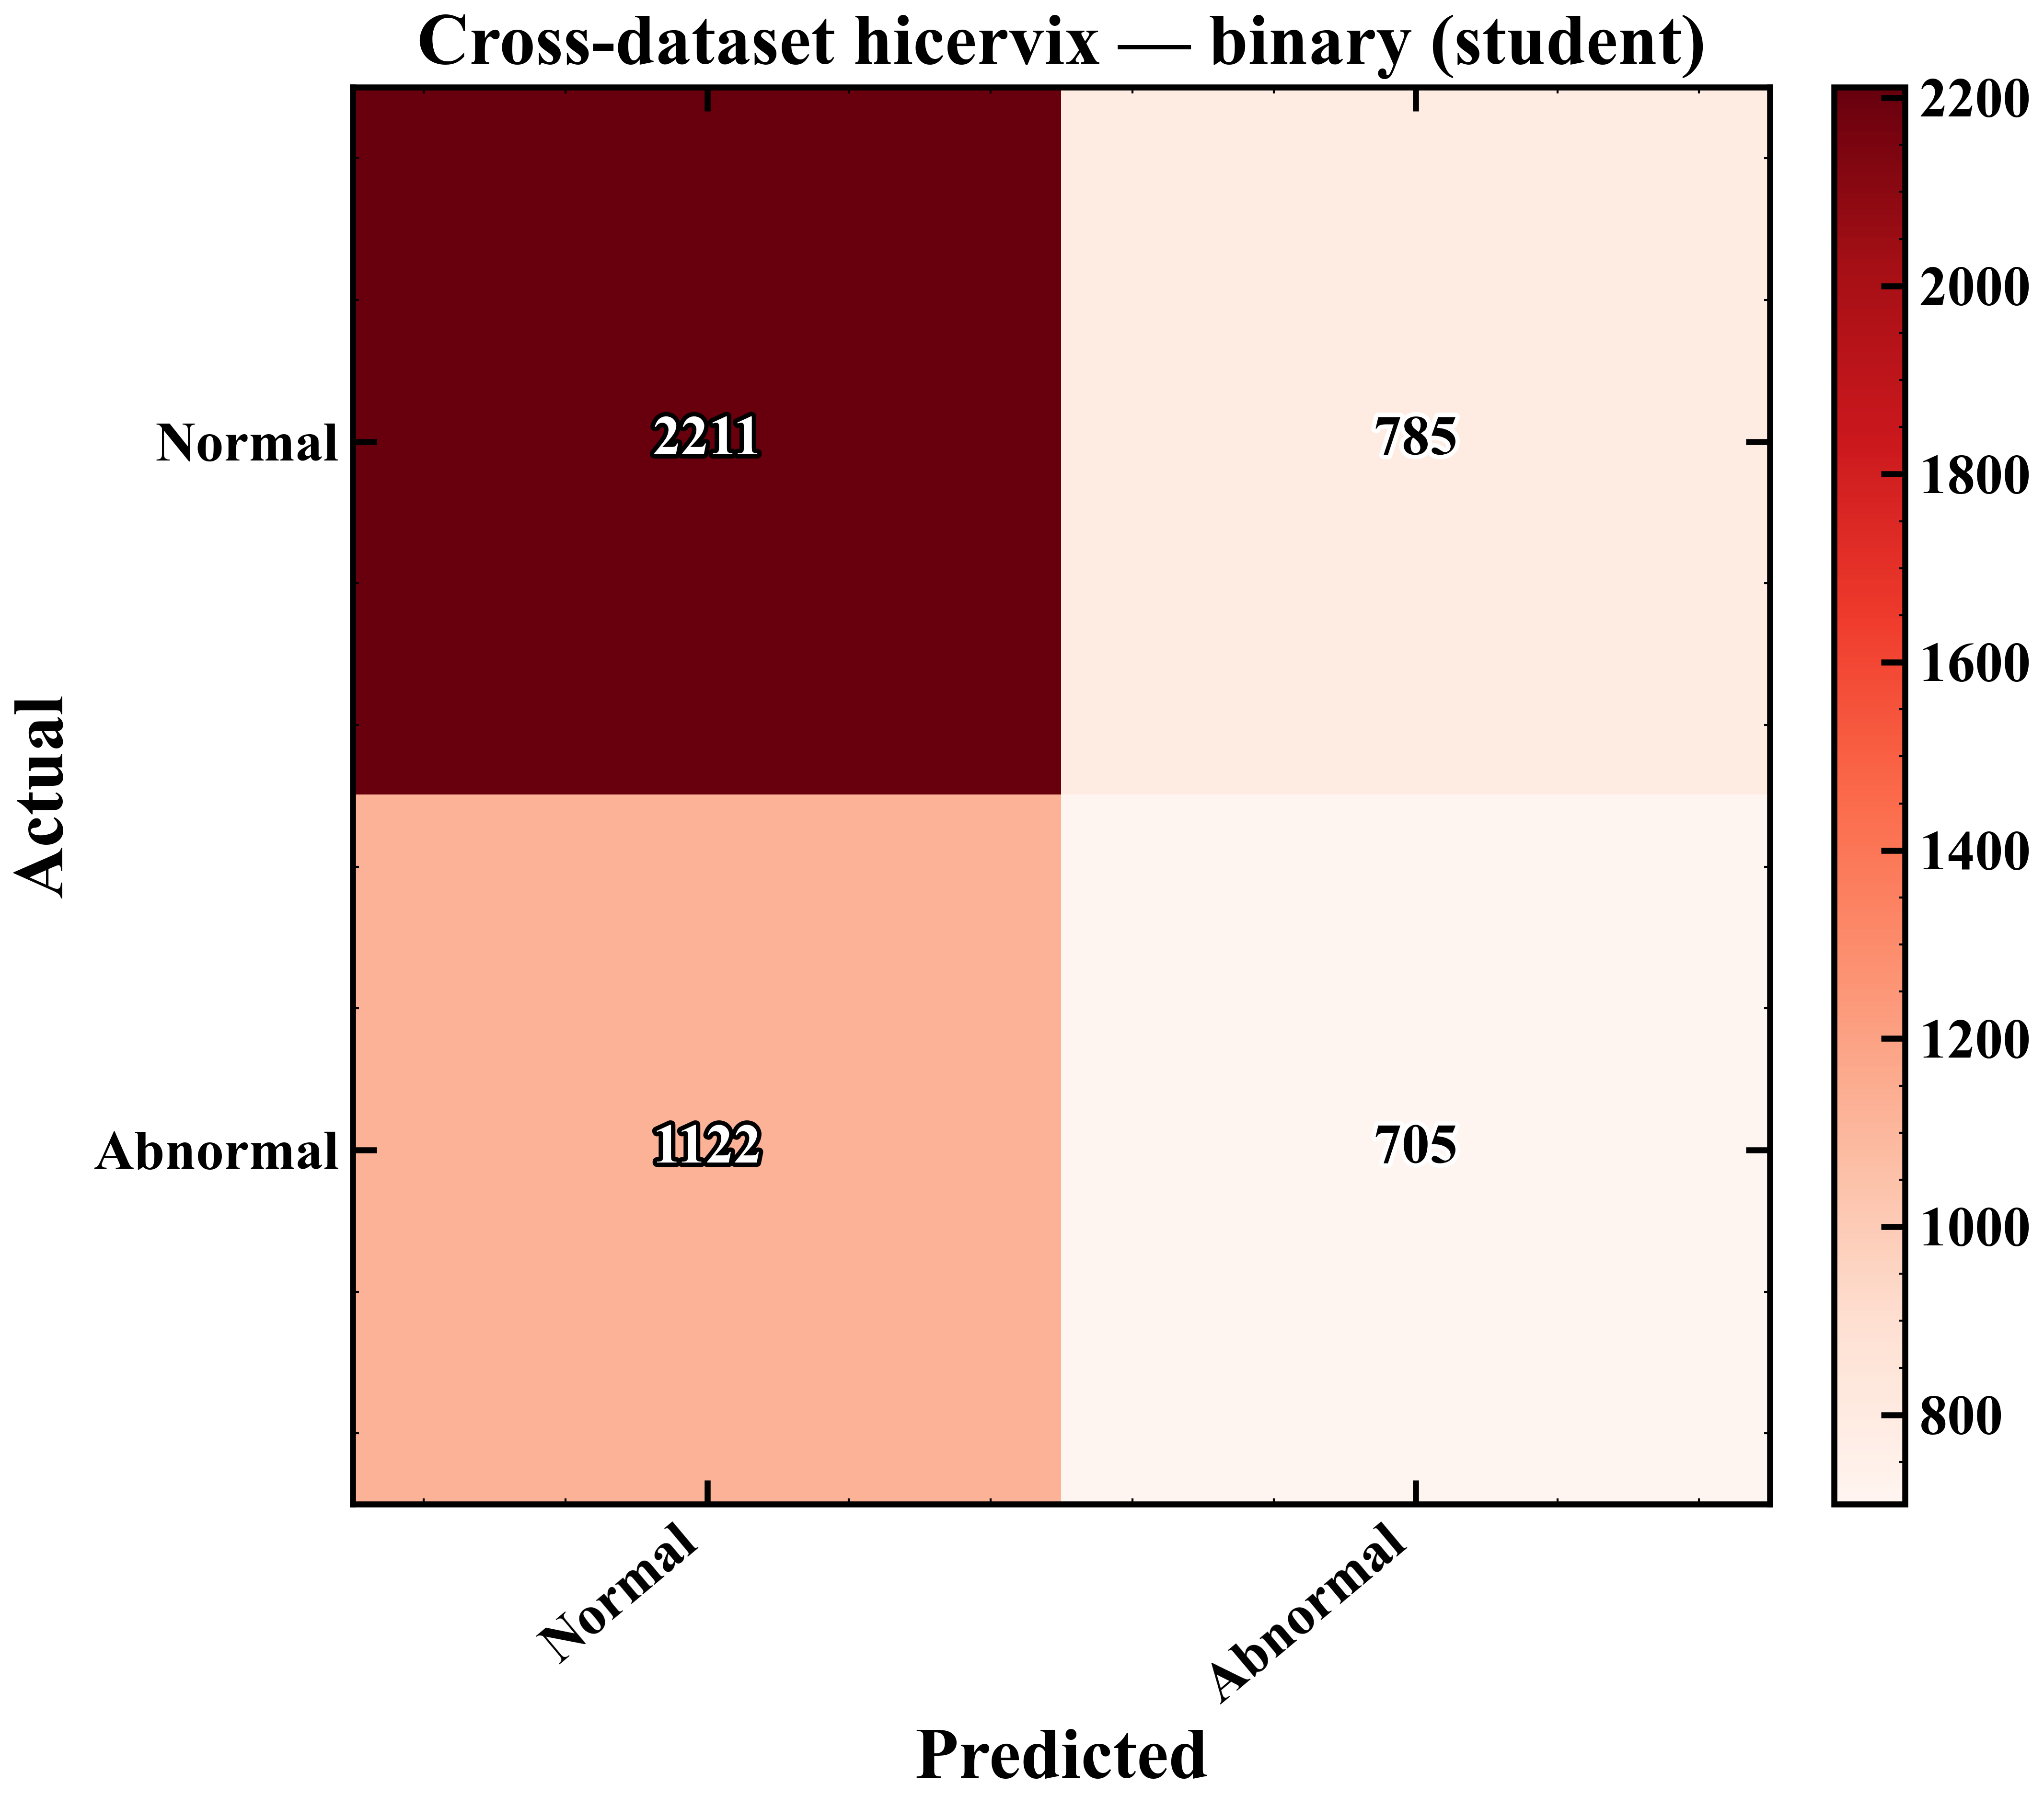

In [3]:
import evaluate
evaluate.cross_dataset_eval('herlev', os.path.join(C.DATA_RAW, 'herlev'), evaluate.herlev_map)
evaluate.cross_dataset_eval('apacc',  os.path.join(C.DATA_RAW, 'apacc'),  evaluate.apacc_map)
evaluate.cross_dataset_eval('hicervix', dataset=evaluate.hicervix_dataset())   # CSV-labeled (test.csv)

show(os.path.join(FIG, 'cm_cross_herlev'), os.path.join(FIG, 'cm_cross_apacc'), os.path.join(FIG, 'cm_cross_hicervix'))

## 7. Grad-CAM explainability
Grad-CAM over the last conv block of the student, one representative cell per class, true -> predicted.

Saved Grad-CAM -> f:\Cervaical Cancer\Legacy_src\results\figures\gradcam_student.png


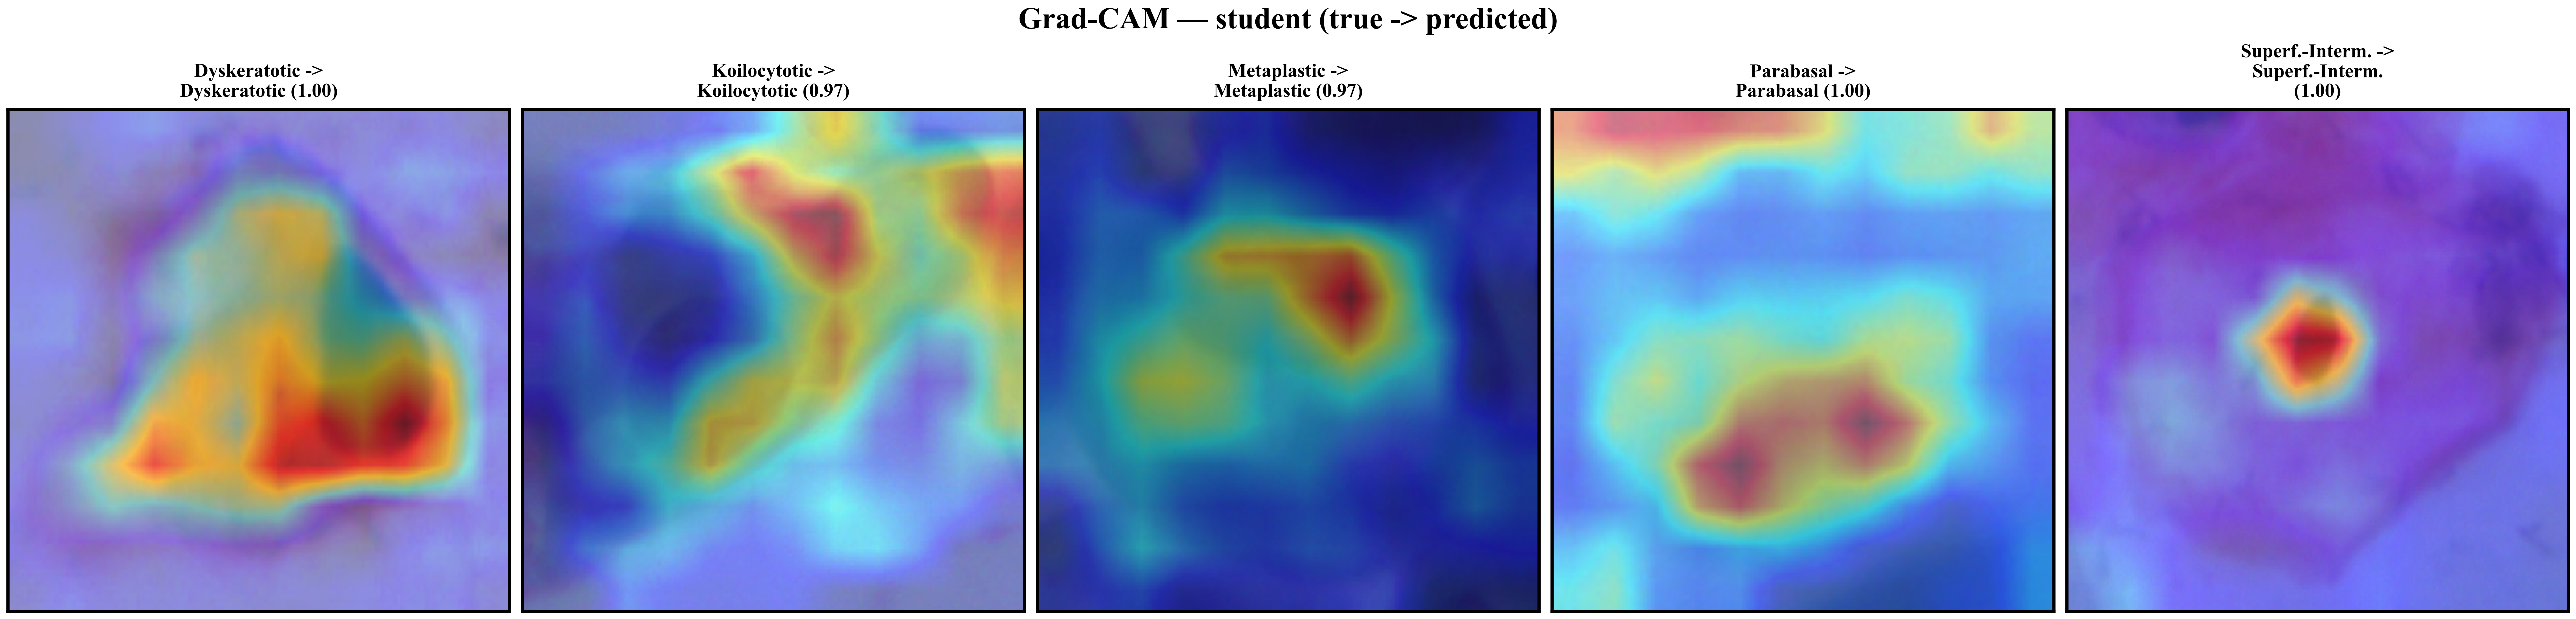

In [4]:
import gradcam
gradcam.run_gradcam('student')
show(os.path.join(FIG, 'gradcam_student'))

## 8. Rebuild any figure from JSON (no re-training)
Every metric is persisted as JSON, so the curves and eval figures can be regenerated from disk alone —
useful after restyling, or on a machine without the GPU/checkpoints.

In [ ]:
# import train, evaluate
# train.curves_from_json()                 # teacher/student training curves <- metrics/train_histories.json
# evaluate.figures_from_json('student')    # cm / roc / reliability <- metrics/predictions_student.json
# evaluate.figures_from_json('teacher')

## 9. Results summary — every artifact produced

In [5]:
for p in sorted(glob.glob(os.path.join(C.RESULTS, '**', '*'), recursive=True)):
    if os.path.isfile(p):
        print(os.path.relpath(p, C.PROJECT))

Legacy_src\results\checkpoints\student-kd_best.pt
Legacy_src\results\checkpoints\student-kd_last.pt
Legacy_src\results\checkpoints\student_b0.pt
Legacy_src\results\checkpoints\teacher-s1_best.pt
Legacy_src\results\checkpoints\teacher-s1_last.pt
Legacy_src\results\checkpoints\teacher-s2_best.pt
Legacy_src\results\checkpoints\teacher-s2_last.pt
Legacy_src\results\checkpoints\teacher_b4.pt
Legacy_src\results\figures\cm_cross_apacc.pdf
Legacy_src\results\figures\cm_cross_apacc.png
Legacy_src\results\figures\cm_cross_herlev.pdf
Legacy_src\results\figures\cm_cross_herlev.png
Legacy_src\results\figures\cm_cross_hicervix.pdf
Legacy_src\results\figures\cm_cross_hicervix.png
Legacy_src\results\figures\cm_student.pdf
Legacy_src\results\figures\cm_student.png
Legacy_src\results\figures\cm_teacher.pdf
Legacy_src\results\figures\cm_teacher.png
Legacy_src\results\figures\eda_class_balance.pdf
Legacy_src\results\figures\eda_class_balance.png
Legacy_src\results\figures\eda_sample_cells.pdf
Legacy_src\r